# Alquiler — 04 Modelo OLS

Modelo de regresión lineal con **statsmodels OLS** para predecir el alquiler mensual de Moscú en **rublos** (`monthly_rent_rub`, target cruda), sobre la matriz de predictores definida en la etapa 03 de feature engineering.

Este notebook compara, de forma coherente y solo con train para seleccionar, los siguientes métodos de selección de variables:

1. **Lasso**
2. **Best Subset Selection (BSS) agrupado o aproximado**
3. **Stepwise** (forward stepwise con BIC)
4. **Random Forest** (como predictor nativo y como selector por importancias)
5. **Modelos manuales** basados en hipótesis de negocio o de vivienda, formulados antes de evaluar test

Además se conservan dos baselines: el **baseline ingenuo de mediana** y el **OLS completo** con todas las features de la etapa 03.

El recorrido es:

1. Objetivo, datos, target, split temporal y precauciones contra fuga de información.
2. Baseline ingenuo y OLS completo.
3. Métodos de selección: BSS, Stepwise, Lasso y Random Forest.
4. Modelos manuales formulados antes de mirar los resultados de test.
5. Reajuste OLS de los subconjuntos seleccionados, cuando corresponda.
6. Comparación uniforme de modelos y features.
7. Diagnóstico del modelo final y límites de interpretación.
8. Registro y verificación en MLflow (experimento `Alquiler_v2`).

> **Advertencia sobre el uso de test.** La selección de variables y el ajuste de hiperparámetros usan únicamente train. Test se abre recién para comparar candidatos ya cerrados. Si se conserva la regla de parsimonia que compara los candidatos en test y elige un OLS dentro del 1 % del mejor RMSE (ver sección 6), entonces **test también se usa para elegir el modelo final**. Por eso, el RMSE del ganador en test **no es una evaluación final independiente**: es el criterio de elección reutilizado como reporte. Una evaluación independiente requeriría un período posterior no usado en ninguna decisión.

## 1. Objetivo, datos, target, split temporal y precauciones contra fuga

**Objetivo.** Predecir `monthly_rent_rub` (alquiler mensual en rublos) y entender qué subconjuntos de features de la etapa 03 sostienen esa predicción con menor complejidad.

**Datos de entrada.** Los artefactos vigentes de la etapa 03: `rentals_train_fe.csv` y `rentals_test_fe.csv` en `data/processed/`. La matriz de features proviene de esa etapa; acá solo se valida que las columnas existan en train y en test, sin crear features nuevas a partir de test.

**Split temporal vigente.** Train: avisos de 2021–2024. Test: avisos de 2025–2026. No se mezcla el orden temporal: ningún ajuste, escalado, grilla ni ranking de esta etapa se calcula con filas de test.

**Precauciones contra fuga de información.**

- La selección de variables (BSS, Stepwise, Lasso, Random Forest y manuales) se define solo con train. Los modelos manuales se formulan en la sección 4, antes de cualquier tabla de test.
- La validación temporal interna usa esquema walk-forward dentro de train: ajustar con el pasado y evaluar en el año siguiente (2022, 2023 y 2024). En cada fold, el escalado y cualquier cantidad necesaria para construir la grilla se ajustan únicamente con la porción de entrenamiento del fold, sin usar la target del fold de validación.
- Las agrupaciones de BSS se construyen sin información de test y sin usar la target de alquiler para agrupar distritos (ver sección 3.1).
- Test se usa en la sección 6 para comparar candidatos cerrados y, si se aplica la regla del 1 %, también para elegir el final. Esa doble función se declara explícitamente y limita la interpretación del resultado del ganador.

In [1]:
from pathlib import Path
import itertools
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)

DATA_DIR = Path("..") / "data"
OUT_DIR = DATA_DIR / "processed"
TARGET = "monthly_rent_rub"
RAIZ = Path("..").resolve()

train = pd.read_csv(OUT_DIR / "rentals_train_fe.csv", parse_dates=["date_posted"])
test = pd.read_csv(OUT_DIR / "rentals_test_fe.csv", parse_dates=["date_posted"])

FEATURES_BASE = (["area_f_z", "metro_f_z", "furnished", "pets_allowed"]
                 + [c for c in train.columns if c.startswith("district_")]
                 + [c for c in train.columns if c.startswith("building_type_")]
                 + [c for c in train.columns if c.startswith("renovation_")])

# Validación de la matriz proveniente de la etapa 03: mismas columnas en train y test.
assert len(FEATURES_BASE) == 140, f"Se esperaban 140 features de la etapa 03, hay {len(FEATURES_BASE)}"
faltantes_train = [c for c in FEATURES_BASE if c not in train.columns]
faltantes_test = [c for c in FEATURES_BASE if c not in test.columns]
assert not faltantes_train, f"Columnas faltantes en train: {faltantes_train}"
assert not faltantes_test, f"Columnas faltantes en test: {faltantes_test}"
assert TARGET in train.columns and TARGET in test.columns
assert train[FEATURES_BASE].isna().sum().sum() == 0, "Hay nulos en la matriz de train"
assert test[FEATURES_BASE].isna().sum().sum() == 0, "Hay nulos en la matriz de test"
assert train["date_posted"].max() < pd.Timestamp("2025-01-01") <= test["date_posted"].min(), "El split temporal no es 2021-2024 / 2025-2026"
print(f"train {len(train):,} filas ({train['date_posted'].min().date()} a {train['date_posted'].max().date()})")
print(f"test  {len(test):,} filas ({test['date_posted'].min().date()} a {test['date_posted'].max().date()}, reservado hasta la comparación)")
print(f"p = {len(FEATURES_BASE)} features validadas en train y test")
_n_district = len([c for c in FEATURES_BASE if c.startswith("district_")])
_n_bt = len([c for c in FEATURES_BASE if c.startswith("building_type_")])
_n_ren = len([c for c in FEATURES_BASE if c.startswith("renovation_")])
print(f"composición: {_n_district} district_* + {_n_bt} building_type_* + {_n_ren} renovation_* + area_f_z, metro_f_z, furnished, pets_allowed")


def fit_ols(cols, datos=None):
    '''Ajusta un OLS con statsmodels sobre train (o `datos`) con las columnas `cols`.

    Manejo numérico: statsmodels resuelve por pseudo-inversa (pinv), por lo que
    columnas colineales o una matriz de rango deficiente no rompen el ajuste;
    los coeficientes de columnas redundantes quedan no identificados y deben
    leerse con esa cautela. Si `cols` está vacía, ajusta un modelo solo con
    intercepto. El conteo de parámetros se reporta siempre aclarando si
    incluye el intercepto.
    '''
    d = train if datos is None else datos
    cols = list(cols)
    y = d[TARGET].astype(float)
    if len(cols) == 0:
        X = pd.DataFrame({"const": 1.0}, index=d.index)
        return sm.OLS(y, X).fit()
    X = sm.add_constant(d[cols].astype(float), has_constant="add")
    return sm.OLS(y, X).fit()


def predict_ols(modelo, cols, datos):
    cols = list(cols)
    if len(cols) == 0:
        return np.full(len(datos), float(modelo.params.iloc[0]))
    return modelo.predict(sm.add_constant(datos[cols].astype(float), has_constant="add"))


def metricas_pred(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return {"R2": float(r2_score(y_real, y_pred)),
            "RMSE_RUB": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            "MAE_RUB": float(mean_absolute_error(y_real, y_pred))}


def walk_forward(fit_predict, anios=(2022, 2023, 2024)):
    '''Walk-forward dentro de train: fit_predict(tr, va) ajusta solo con el pasado.

    Devuelve (tabla por fold, RMSE medio, MAE medio). La selección y los
    hiperparámetros nunca ven el año de validación de cada fold.
    '''
    filas = []
    for anio in anios:
        tr = train[train["date_posted"].dt.year < anio]
        va = train[train["date_posted"].dt.year == anio]
        if len(tr) == 0 or len(va) == 0:
            continue
        pred = fit_predict(tr, va)
        filas.append({"validacion": anio, "n": len(va), **metricas_pred(va[TARGET], pred)})
    t = pd.DataFrame(filas)
    if t.empty:
        return t, np.nan, np.nan
    return t, float(t["RMSE_RUB"].mean()), float(t["MAE_RUB"].mean())


def metricas_wf_ols(cols):
    '''Métricas walk-forward de un OLS con subconjunto fijo, reajustado por fold solo con el pasado.'''
    def fp(tr, va, cols=cols):
        m = fit_ols(cols, datos=tr)
        return predict_ols(m, cols, va)
    tabla, rm, ma = walk_forward(fp)
    # R2 walk-forward: promedio de los R2 por fold (cada fold se ajusta solo con su pasado).
    r2_wf = float(tabla["R2"].mean()) if not tabla.empty else np.nan
    return {"R2": r2_wf, "RMSE_RUB": rm, "MAE_RUB": ma}, tabla


def bloque_de(col):
    if col.startswith("district_"): return "district"
    if col.startswith("building_type_"): return "building_type"
    if col.startswith("renovation_"): return "renovation"
    return "continuas_binarias"

train 14,820 filas (2021-01-01 a 2024-12-31)
test  4,841 filas (2025-01-01 a 2026-04-29, reservado hasta la comparación)
p = 140 features validadas en train y test
composición: 128 district_* + 5 building_type_* + 3 renovation_* + area_f_z, metro_f_z, furnished, pets_allowed


### La batería OLS y las estadísticas clásicas

Cada OLS relevante pasa por la misma batería: ajuste global, colinealidad (VIF), tabla de coeficientes con errores estándar, estadístico t, p-valores e intervalos del 95 %, y diagnóstico de residuos (residuos vs. ajustados, QQ-plot, Scale-Location e histograma), junto con Jarque-Bera, Breusch-Pagan, Durbin-Watson y distancia de Cook máxima.

Las estadísticas clásicas de cada OLS —R², R² ajustado, estadístico F y su p-valor, AIC, BIC y log-likelihood— se calculan **a partir del OLS ajustado con train**, sobre la misma target y las mismas observaciones de train, para que AIC y BIC sean comparables entre OLS. El R² ajustado reportado es el del ajuste en train; no se calcula un R² ajustado de test.

> **Inferencia post-selección.** Los p-valores, intervalos de confianza y estadísticos de los OLS reajustados después de seleccionar variables con los mismos datos de train son **descriptivos y exploratorios**. No constituyen inferencia independiente posterior a la selección, porque el mismo train eligió el subconjunto y estimó los coeficientes.

In [2]:
def tabla_coeficientes(modelo):
    ci = modelo.conf_int()
    return pd.DataFrame({
        "feature": modelo.params.index,
        "coef": modelo.params.to_numpy(dtype=float),
        "std_err": modelo.bse.to_numpy(dtype=float),
        "t": modelo.tvalues.to_numpy(dtype=float),
        "p_valor": modelo.pvalues.to_numpy(dtype=float),
        "IC95_inf": ci[0].to_numpy(dtype=float),
        "IC95_sup": ci[1].to_numpy(dtype=float),
    })


def estadisticas_ols(modelo, cols):
    '''Estadísticas clásicas del OLS ajustado en train. p cuenta features sin intercepto.'''
    cols = list(cols)
    try:
        f_val = float(modelo.fvalue)
    except Exception:
        f_val = np.nan
    try:
        f_p = float(modelo.f_pvalue)
    except Exception:
        f_p = np.nan
    return {"R2_train": float(modelo.rsquared), "Adj_R2_train": float(modelo.rsquared_adj),
            "F": f_val, "F_pvalor": f_p, "AIC": float(modelo.aic), "BIC": float(modelo.bic),
            "LogLik": float(modelo.llf), "n_obs": int(modelo.nobs),
            "n_features_sin_intercepto": len(cols), "n_parametros_con_intercepto": len(cols) + 1}


def bateria_ols(modelo, cols, titulo):
    cols = list(cols)
    est = estadisticas_ols(modelo, cols)
    pred_tr = predict_ols(modelo, cols, train)
    met_pred = metricas_pred(train[TARGET], pred_tr)
    X = train[cols].astype(float) if cols else pd.DataFrame(index=train.index)
    if len(cols) > 1:
        corr = np.corrcoef(X.to_numpy(), rowvar=False)
        corr = np.nan_to_num(corr, nan=0.0)
        vif = pd.Series(np.diag(np.linalg.pinv(corr)), index=cols).sort_values(ascending=False)
        vif_max = float(vif.max()) if len(vif) else np.nan
    else:
        vif = pd.Series(dtype=float)
        vif_max = np.nan
    coef = tabla_coeficientes(modelo)
    jb = jarque_bera(modelo.resid)
    bp = het_breuschpagan(modelo.resid, modelo.model.exog)
    try:
        cook_max = float(modelo.get_influence().cooks_distance[0].max())
    except Exception:
        cook_max = np.nan
    diag = {"JarqueBera_p": float(jb[1]), "BreuschPagan_p": float(bp[1]),
            "DurbinWatson": float(durbin_watson(modelo.resid)), "Cook_max": cook_max}
    rango = int(np.linalg.matrix_rank(modelo.model.exog)) if hasattr(modelo, "model") else len(cols) + 1
    print(f"===== {titulo} =====")
    resumen = {**est, **{f"{k}_train": v for k, v in met_pred.items()}, **diag,
               "VIF_max": vif_max, "rango_exog": rango}
    print(pd.Series(resumen).round(4).to_string())
    n_ns = int((coef["p_valor"] > 0.05).sum())
    print(f"VIF máximo: {vif_max:.2f} | coeficientes con p>0,05: {n_ns} de {len(coef)} (lectura descriptiva, ver nota post-selección)")
    display(coef.round(3))

    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    fitted, resid = np.asarray(modelo.fittedvalues, dtype=float), np.asarray(modelo.resid, dtype=float)
    axes[0, 0].scatter(fitted, resid, s=6, alpha=0.35, color="steelblue")
    axes[0, 0].axhline(0, color="crimson", lw=1.2); axes[0, 0].set_title("Residuos vs ajustados")
    axes[0, 0].set_xlabel("ajustados (RUB)"); axes[0, 0].set_ylabel("residuos (RUB)")
    (osm, osr), (slope, intercept, _r) = stats.probplot(resid, dist="norm")
    axes[0, 1].scatter(osm, osr, s=6, alpha=0.35, color="steelblue")
    axes[0, 1].plot(osm, slope * np.array(osm) + intercept, color="crimson", lw=1.2)
    axes[0, 1].set_title("QQ-plot de residuos")
    escala = np.sqrt(np.abs(resid / resid.std())) if resid.std() > 0 else np.zeros_like(resid)
    axes[1, 0].scatter(fitted, escala, s=6, alpha=0.35, color="steelblue")
    axes[1, 0].set_title("Scale-Location"); axes[1, 0].set_xlabel("ajustados (RUB)")
    axes[1, 1].hist(resid, bins=50, color="lightsteelblue", edgecolor="white")
    axes[1, 1].set_title("Histograma de residuos (RUB)")
    fig.suptitle(f"Diagnóstico — {titulo}", y=1.01)
    plt.tight_layout(); plt.show()
    return {"estadisticas": est, "metricas_train": met_pred, "diagnostico": diag,
            "vif_max": vif_max, "vif": vif, "coef": coef, "figura": fig}

## 2. Baselines en escalera

### 2.1 El piso: predecir siempre la mediana

Antes de cualquier regresión, la vara más baja: para todo aviso, predecir la mediana del alquiler calculada solo con la porción de entrenamiento que corresponda. No usa ninguna característica y por eso es el piso que cualquier modelo tiene que superar por un margen que justifique su complejidad. Sus métricas se calculan en la celda siguiente a partir de los datos actuales, sin valores fijos de ejecuciones anteriores.

In [3]:
mediana_train = float(train[TARGET].median())

def _pred_naive(tr, va):
    return np.full(len(va), float(tr[TARGET].median()))

tabla_wf_naive, rmse_wf_naive, mae_wf_naive = walk_forward(_pred_naive)
y_2024 = train.loc[train["date_posted"].dt.year == 2024, TARGET]
pred_naive_2024 = np.full(len(y_2024), float(train.loc[train["date_posted"].dt.year < 2024, TARGET].median()))
m_naive_val2024 = metricas_pred(y_2024, pred_naive_2024)
m_naive_train = metricas_pred(train[TARGET], np.full(len(train), mediana_train))
m_naive_test = metricas_pred(test[TARGET], np.full(len(test), mediana_train))
base_naive = {"mediana_train_RUB": mediana_train,
              **{f"{k}_train": v for k, v in m_naive_train.items()},
              **{f"{k}_val2024": v for k, v in m_naive_val2024.items()},
              **{f"{k}_test": v for k, v in m_naive_test.items()},
              "RMSE_WF": rmse_wf_naive, "MAE_WF": mae_wf_naive}
print(f"Baseline ingenuo: mediana de train = {mediana_train:,.0f} RUB")
print(f"  train: RMSE = {m_naive_train['RMSE_RUB']:,.0f} RUB | MAE = {m_naive_train['MAE_RUB']:,.0f} RUB | R2 = {m_naive_train['R2']:.3f}")
print(f"  validación 2024 (mediana 2021-2023): RMSE = {m_naive_val2024['RMSE_RUB']:,.0f} RUB | MAE = {m_naive_val2024['MAE_RUB']:,.0f} RUB")
print(f"  walk-forward 2022-2024: RMSE medio = {rmse_wf_naive:,.0f} RUB | MAE medio = {mae_wf_naive:,.0f} RUB")
display(tabla_wf_naive.round(2))

Baseline ingenuo: mediana de train = 45,000 RUB
  train: RMSE = 25,113 RUB | MAE = 19,065 RUB | R2 = -0.040
  validación 2024 (mediana 2021-2023): RMSE = 28,062 RUB | MAE = 21,140 RUB
  walk-forward 2022-2024: RMSE medio = 26,616 RUB | MAE medio = 19,780 RUB


,validacion,n,R2,RMSE_RUB,MAE_RUB
0,2022,3764,-0.10,24833.58,18177.67
1,2023,3747,-0.19,26953.74,20022.06
2,2024,3705,-0.18,28062.04,21140.12


### 2.2 El techo de la matriz: el OLS completo

El segundo escalón ajusta todas las features de la etapa 03 sin seleccionar nada. No es el modelo final: es el techo que la matriz puede dar hoy y la referencia contra la que toda poda posterior tiene que demostrar que perder columnas no cuesta demasiado error. Pasa por la misma batería de diagnóstico que el modelo final, para que la comparación sea consistente.

===== Baseline OLS completo =====


R2_train                            0.8998
Adj_R2_train                        0.8988
F                                 941.1183
F_pvalor                            0.0000
AIC                            307954.9155
BIC                            309027.0419
LogLik                        -153836.4578
n_obs                           14820.0000
n_features_sin_intercepto         140.0000
n_parametros_con_intercepto       141.0000
RMSE_RUB_train                   7796.1808
MAE_RUB_train                    6068.9101
JarqueBera_p                        0.0000
BreuschPagan_p                      0.0000
DurbinWatson                        2.0220
Cook_max                            0.0013
VIF_max                             2.8657
rango_exog                        141.0000
VIF máximo: 2.87 | coeficientes con p>0,05: 5 de 141 (lectura descriptiva, ver nota post-selección)


,feature,coef,std_err,t,p_valor,IC95_inf,IC95_sup
0,const,48721.756,689.220,70.691,0.0,47370.798,50072.714
1,area_f_z,10243.779,64.620,158.524,0.0,10117.117,10370.442
2,metro_f_z,-6706.526,108.930,-61.567,0.0,-6920.042,-6493.010
3,furnished,3516.396,141.682,24.819,0.0,3238.681,3794.110
4,pets_allowed,-1214.531,140.529,-8.643,0.0,-1489.986,-939.076
...,...,...,...,...,...,...,...
136,building_type_monolith,8292.171,195.746,42.362,0.0,7908.484,8675.857
137,building_type_stalin,12260.950,317.518,38.615,0.0,11638.574,12883.326
138,renovation_designer,14490.754,224.434,64.566,0.0,14050.836,14930.673
139,renovation_euro,6599.001,145.869,45.239,0.0,6313.079,6884.924


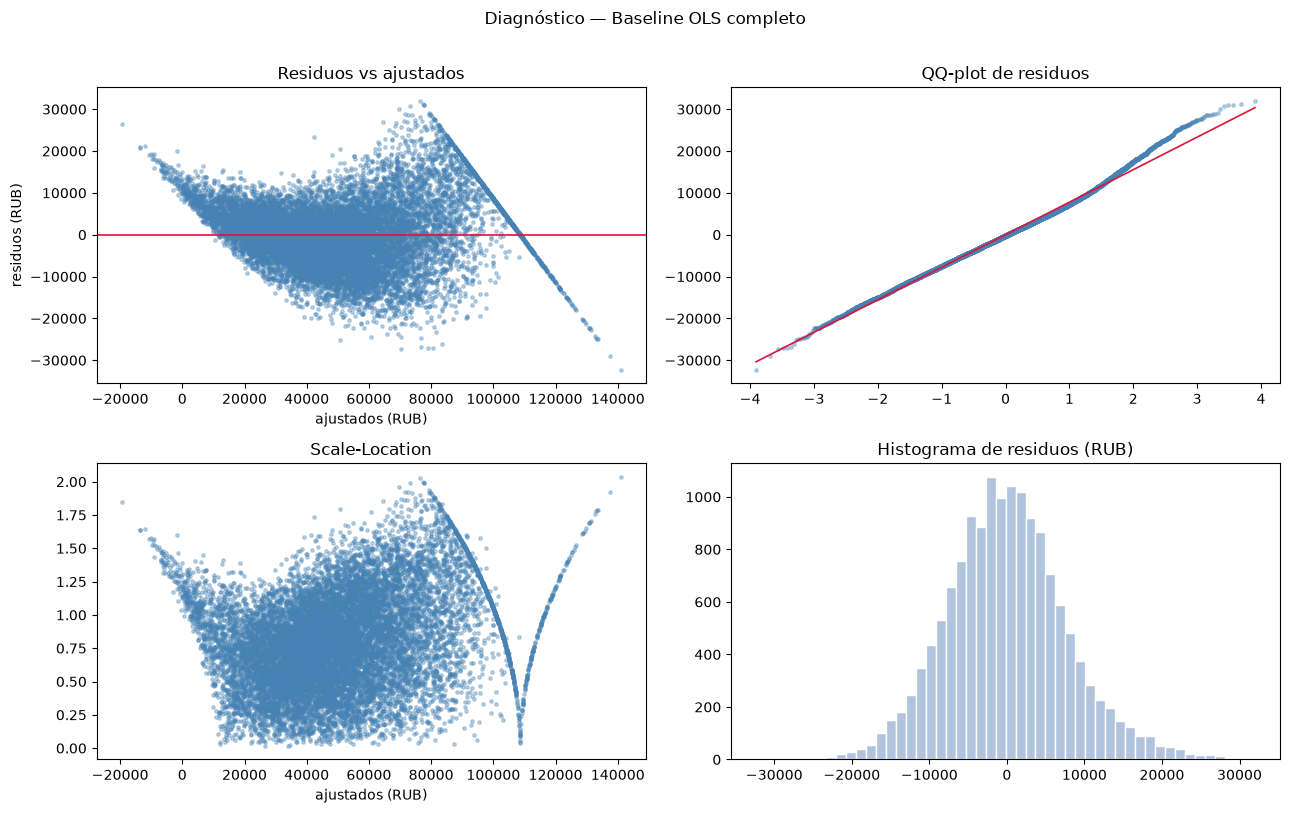

                            OLS Regression Results                            
Dep. Variable:       monthly_rent_rub   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                     941.1
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:22:40   Log-Likelihood:            -1.5384e+05
No. Observations:               14820   AIC:                         3.080e+05
Df Residuals:                   14679   BIC:                         3.090e+05
Df Model:                         140                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


In [4]:
ols_completo = fit_ols(FEATURES_BASE)
res_completo = bateria_ols(ols_completo, FEATURES_BASE, "Baseline OLS completo")
print(ols_completo.summary().as_text()[:1500])

## 3. Métodos de selección de variables (solo train)

Cuatro métodos automáticos buscan las features que más pesan, cada uno con su criterio nativo y **sin tocar test**: BSS agrupado y Stepwise eligen por BIC sobre train; Lasso y Random Forest recorren sus hiperparámetros con validación temporal walk-forward dentro de train. Recién con todos los candidatos cerrados (incluidos los manuales de la sección 4) se abre test en la sección 6.

### 3.1 Best Subset Selection agrupado o aproximado (BSS)

Con 140 features, una búsqueda exhaustiva sobre los $2^{140}$ subconjuntos de columnas no es viable. Por eso este notebook implementa un **BSS agrupado o aproximado**: la búsqueda exhaustiva corre sobre **bloques** de columnas, no sobre columnas individuales. No debe presentarse como búsqueda exhaustiva sobre las 140 columnas.

**Cómo se construyen los bloques.** El resto de la matriz forma bloques fijos: `area_f_z`, `metro_f_z`, `furnished` y `pets_allowed` como bloques unitarios, todas las `building_type_*` como un bloque y todas las `renovation_*` como un bloque. Los distritos se agrupan de dos maneras alternativas, ambas sin usar test ni la target de alquiler:

- **Por `okrug`**: cada distrito se asigna a su zona administrativa según `rentals.csv`. Resultan bloques distritales por zona, más los bloques del resto.
- **Por nivel de precio de venta**: cada distrito se asigna al tercil de la mediana de `secondary_price_per_sqm` calculada solo con meses anteriores a 2025 en `district_prices_monthly.csv` (período de train). Agrupar por alquiler promedio del distrito no es una opción, porque construiría los grupos con la propia target.

**Criterio y combinaciones evaluadas.** Para cada cantidad de bloques $k$, se evalúan todas las combinaciones de $k$ bloques y se conserva la de menor RSS en train; el campeón de la corrida es el subconjunto de bloques con **menor BIC** en train, con $\text{BIC} = n \log(\text{RSS}/n) + (k_{\text{columnas}}+1)\log(n)$, donde $k_{\text{columnas}}$ cuenta columnas sin intercepto y el $+1$ es el intercepto. El total de subconjuntos de bloques evaluados es $2^{n_{\text{bloques}}}$, cantidad que la celda siguiente calcula e informa para cada agrupamiento. Si una búsqueda exacta sobre un espacio reducido es factible, ese espacio es el de bloques: se reduce de 140 columnas a un puñado de bloques a costa de no poder podar distritos de a uno dentro de un bloque.

por okrug: 17 bloques | subconjuntos de bloques evaluados: 131,072 de 131,072 posibles (2^17)
  campeón BIC: 17 bloques, 140 columnas, BIC = 266,970 (7 s)
  criterio: menor RSS por tamaño de bloques y menor BIC global, todo en train. Esto es BSS agrupado/aproximado, no exhaustivo sobre las 140 columnas.


,k_bloques,n_columnas,RSS,BIC,bloques
0,0,0,8.985910e+12,299713.7,
1,1,1,5.581638e+12,292666.3,metro_f_z
2,2,2,4.004477e+12,287754.7,"area_f_z, metro_f_z"
3,3,12,2.876769e+12,282949.1,"area_f_z, metro_f_z, district_CAO"
4,4,15,2.488332e+12,280828.2,"area_f_z, metro_f_z, renovation, district_CAO"
5,5,27,2.122988e+12,278590.2,"area_f_z, metro_f_z, renovation, district_CAO,..."
6,6,32,1.821254e+12,276366.3,"area_f_z, metro_f_z, building_type, renovation..."
7,7,44,1.560499e+12,274191.6,"area_f_z, metro_f_z, building_type, renovation..."
8,8,52,1.364282e+12,272276.9,"area_f_z, metro_f_z, building_type, renovation..."
9,9,62,1.239833e+12,270955.4,"area_f_z, metro_f_z, building_type, renovation..."


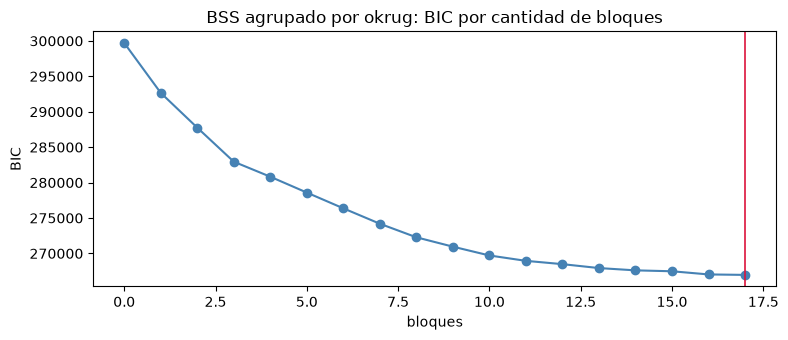

por nivel de precio de venta: 9 bloques | subconjuntos de bloques evaluados: 512 de 512 posibles (2^9)
  campeón BIC: 9 bloques, 140 columnas, BIC = 266,970 (0 s)
  criterio: menor RSS por tamaño de bloques y menor BIC global, todo en train. Esto es BSS agrupado/aproximado, no exhaustivo sobre las 140 columnas.


,k_bloques,n_columnas,RSS,BIC,bloques
0,0,0,8.985910e+12,299713.7,
1,1,42,4.784836e+12,290777.4,district_venta_alta
2,2,43,3.165668e+12,284665.0,"area_f_z, district_venta_alta"
3,3,44,2.010901e+12,277949.6,"area_f_z, metro_f_z, district_venta_alta"
4,4,47,1.612963e+12,274710.4,"area_f_z, metro_f_z, renovation, district_vent..."
5,5,90,1.311092e+12,272052.5,"area_f_z, metro_f_z, renovation, district_vent..."
6,6,95,1.020820e+12,268391.8,"area_f_z, metro_f_z, building_type, renovation..."
7,7,138,9.432199e+11,267633.0,"area_f_z, metro_f_z, building_type, renovation..."
8,8,139,9.053496e+11,267035.3,"area_f_z, metro_f_z, furnished, building_type,..."
9,9,140,9.007660e+11,266969.7,"area_f_z, metro_f_z, furnished, pets_allowed, ..."


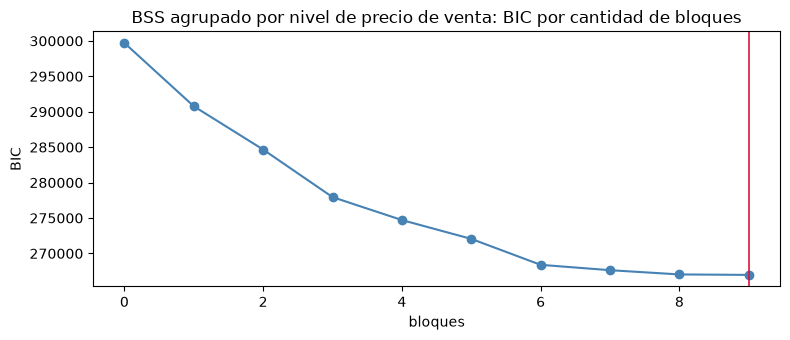

In [5]:
base_rentals = pd.read_csv(DATA_DIR / "rentals.csv", usecols=["district", "okrug"])
mapa_okrug = base_rentals.drop_duplicates().set_index("district")["okrug"].to_dict()
monthly = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
nivel_venta = (monthly[monthly["year_month"] < "2025-01"]
               .groupby("district")["secondary_price_per_sqm"].median())
terciles = pd.qcut(nivel_venta, 3, labels=["venta_baja", "venta_media", "venta_alta"])

def bloques_distrito(criterio):
    grupos = {}
    for col in [c for c in FEATURES_BASE if c.startswith("district_")]:
        distrito = col[len("district_"):]
        clave = mapa_okrug[distrito] if criterio == "okrug" else str(terciles.loc[distrito])
        grupos.setdefault(f"district_{clave}", []).append(col)
    return grupos

BLOQUES_RESTO = {"area_f_z": ["area_f_z"], "metro_f_z": ["metro_f_z"],
                 "furnished": ["furnished"], "pets_allowed": ["pets_allowed"],
                 "building_type": [c for c in FEATURES_BASE if c.startswith("building_type_")],
                 "renovation": [c for c in FEATURES_BASE if c.startswith("renovation_")]}

Xg = np.column_stack([np.ones(len(train)), train[FEATURES_BASE].astype(float).to_numpy()])
yg = train[TARGET].astype(float).to_numpy()
XtX, Xty, yty = Xg.T @ Xg, Xg.T @ yg, float(yg @ yg)
pos = {c: i + 1 for i, c in enumerate(FEATURES_BASE)}
N_TR = len(train)

def rss_subconjunto(idx_cols):
    '''RSS en train de un subconjunto, vía XtX. Ante singularidad usa pseudo-inversa.'''
    idx = [0] + [pos[c] for c in idx_cols]
    A = XtX[np.ix_(idx, idx)]
    b = Xty[idx]
    try:
        beta = np.linalg.solve(A, b)
        rss = float(yty - b @ beta)
    except np.linalg.LinAlgError:
        beta = np.linalg.pinv(A) @ b
        rss = float(yty - 2.0 * (b @ beta) + beta @ A @ beta)
    return max(rss, 0.0)

def bic_de(rss, k_cols):
    return N_TR * np.log(max(rss, 1e-9) / N_TR) + (k_cols + 1) * np.log(N_TR)

def best_subset(unidades, nombre):
    t0 = time.time()
    nombres = list(unidades.keys())
    n_bloques = len(nombres)
    total_combinaciones = 2 ** n_bloques
    mejor_por_k = {}
    evaluadas = 0
    for k in range(n_bloques + 1):
        mejor = None
        for combo in itertools.combinations(nombres, k):
            evaluadas += 1
            cols_c = [c for u in combo for c in unidades[u]]
            rss = rss_subconjunto(cols_c)
            if mejor is None or rss < mejor[1]:
                mejor = (combo, rss, cols_c)
        mejor_por_k[k] = mejor
    filas = []
    for k, (combo, rss, cols_c) in mejor_por_k.items():
        filas.append({"k_bloques": k, "n_columnas": len(cols_c), "RSS": rss,
                      "BIC": bic_de(rss, len(cols_c)), "bloques": ", ".join(combo)})
    tabla = pd.DataFrame(filas)
    campeon = tabla.loc[tabla["BIC"].idxmin()]
    cols_campeon = mejor_por_k[int(campeon["k_bloques"])][2]
    print(f"{nombre}: {n_bloques} bloques | subconjuntos de bloques evaluados: {evaluadas:,} de {total_combinaciones:,} posibles (2^{n_bloques})")
    print(f"  campeón BIC: {int(campeon['k_bloques'])} bloques, {int(campeon['n_columnas'])} columnas, BIC = {campeon['BIC']:,.0f} ({time.time()-t0:.0f} s)")
    print(f"  criterio: menor RSS por tamaño de bloques y menor BIC global, todo en train. Esto es BSS agrupado/aproximado, no exhaustivo sobre las 140 columnas.")
    display(tabla.round(1))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(tabla["k_bloques"], tabla["BIC"], marker="o", color="steelblue")
    ax.axvline(campeon["k_bloques"], color="crimson", lw=1.2)
    ax.set_title(f"BSS agrupado {nombre}: BIC por cantidad de bloques")
    ax.set_xlabel("bloques"); ax.set_ylabel("BIC"); plt.tight_layout(); plt.show()
    return {"tabla": tabla, "cols": list(cols_campeon), "figura": fig, "k": int(campeon["k_bloques"]),
            "n_bloques": n_bloques, "combinaciones_evaluadas": int(evaluadas)}

bss_okrug = best_subset({**BLOQUES_RESTO, **bloques_distrito("okrug")}, "por okrug")
bss_precio = best_subset({**BLOQUES_RESTO, **bloques_distrito("precio")}, "por nivel de precio de venta")

### 3.2 Stepwise hacia adelante con BIC

El stepwise libre agrega de a una las columnas de la matriz: en cada paso prueba todas las que faltan y se queda con la que más baja el BIC en train.

- **Criterio de entrada:** en cada paso entra la columna candidata con menor BIC resultante.
- **Criterio de parada:** se detiene cuando ninguna incorporación mejora el BIC en al menos 2 puntos, o cuando se alcanza el tope de columnas.
- **Datos:** todo el recorrido se ajusta con train, vía el RSS sobre la misma matriz `XtX` de la sección anterior.

A diferencia del BSS agrupado, este procedimiento puede podar distritos de a uno, al precio de tomar decisiones locales y voraces que no miran combinaciones.

Stepwise forward con BIC: 109 columnas seleccionadas de 140 (entrada: menor BIC; parada: mejora < 2.0 puntos de BIC)


,paso,columna,BIC,n_columnas
102,102,district_Biryulyovo Vostochnoye,267252.1,102
103,103,district_Golyanovo,267239.5,103
104,104,district_Veshnyaki,267227.3,104
105,105,district_Ivanovskoye,267214.3,105
106,106,district_Orekhovo-Borisovo Yuzhnoye,267206.6,106
107,107,district_Kosino-Ukhtomsky,267200.4,107
108,108,district_Brateyevo,267193.3,108
109,109,district_Molzhaninovsky,267190.9,109


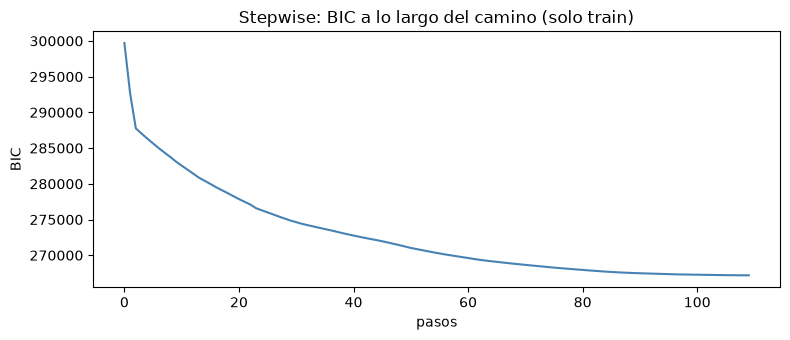

In [6]:
def forward_stepwise(mejora_minima=2.0, tope=140):
    sel, restantes = [], list(FEATURES_BASE)
    rss_actual = rss_subconjunto([])
    bic_actual = bic_de(rss_actual, 0)
    historial = [{"paso": 0, "columna": "(intercepto)", "BIC": bic_actual, "n_columnas": 0}]
    for paso in range(1, tope + 1):
        mejor = None
        for c in restantes:
            rss_c = rss_subconjunto(sel + [c])
            bic_c = bic_de(rss_c, len(sel) + 1)
            if mejor is None or bic_c < mejor[1]:
                mejor = (c, bic_c, rss_c)
        if mejor is None or bic_actual - mejor[1] < mejora_minima:
            break
        sel.append(mejor[0]); restantes.remove(mejor[0])
        bic_actual, rss_actual = mejor[1], mejor[2]
        historial.append({"paso": paso, "columna": mejor[0], "BIC": bic_actual, "n_columnas": len(sel)})
    tabla_h = pd.DataFrame(historial)
    print(f"Stepwise forward con BIC: {len(sel)} columnas seleccionadas de {len(FEATURES_BASE)} (entrada: menor BIC; parada: mejora < {mejora_minima} puntos de BIC)")
    display(tabla_h.tail(8).round(1))
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(tabla_h["paso"], tabla_h["BIC"], color="steelblue")
    ax.set_title("Stepwise: BIC a lo largo del camino (solo train)"); ax.set_xlabel("pasos"); ax.set_ylabel("BIC")
    plt.tight_layout(); plt.show()
    return {"cols": list(sel), "tabla": tabla_h, "figura": fig}

sws = forward_stepwise()

### 3.3 Lasso con validación temporal dentro de train

Lasso encoge los coeficientes con una penalización $L_1$ de intensidad `alpha` y apaga los que no pagan su penalización. El hiperparámetro se elige **solo con validación temporal dentro de train**:

- Se trabaja con un `Pipeline` de `StandardScaler` + `Lasso`, para que el procedimiento sea reproducible y los coeficientes puedan asociarse con los nombres originales de las features. El escalado se ajusta únicamente con la porción de entrenamiento de cada fold.
- La grilla se define como fracciones del `alpha` que anula todos los coeficientes. En cada fold, ese `alpha` máximo y el escalado se calculan **solo con la porción de entrenamiento del fold**, sin usar la target del fold de validación para construir la selección ni la grilla. Se promedia el RMSE walk-forward por fracción de grilla y se elige la fracción ganadora; el `alpha` final es esa fracción aplicada al `alpha` máximo de todo train, con el pipeline reajustado en todo train.
- **Tolerancia explícita de selección:** una feature queda seleccionada si el valor absoluto de su coeficiente de Lasso en escala estandarizada supera `1e-8`. Abajo se informan el `alpha` elegido, la cantidad de features con coeficiente distinto de cero según esa tolerancia y la tabla completa de coeficientes asociada a cada nombre original (coeficiente en escala estandarizada y su equivalente en rublos por unidad original).

Lasso: fracción elegida por walk-forward = 0.0001 | alpha final en todo train = 1.516
  RMSE walk-forward de la fracción elegida = 8,702 RUB | MAE = 6,652 RUB


,fraccion,RMSE_WF,MAE_WF,R2_WF
0,0.0001,8702.1509,6652.1260,0.8763
1,0.0001,8704.0001,6652.8816,0.8763
2,0.0002,8707.0503,6654.4046,0.8762
3,0.0003,8711.3201,6656.1459,0.8761
4,0.0005,8718.2399,6658.6559,0.8759
5,0.0007,8728.0623,6662.5338,0.8756
6,0.0010,8742.9816,6668.2286,0.8751
7,0.0015,8760.5571,6674.1868,0.8746
8,0.0022,8786.2227,6683.7517,0.8739
9,0.0032,8825.2902,6699.6173,0.8728


Advertencia: el óptimo walk-forward quedó en el borde inferior de la grilla; dentro del rango evaluado, la validación temporal prefiere la penalización más débil. En este caso Lasso casi no poda features y su subconjunto debe leerse con esa salvedad, no como un óptimo interior.


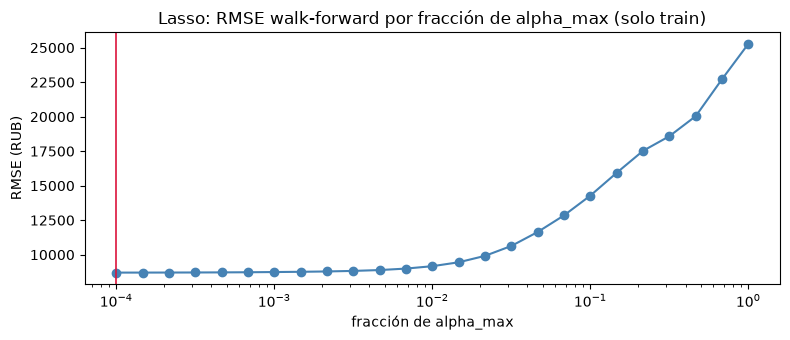

Lasso con tolerancia |coef estandarizado| > 1e-08: 140 features con coeficiente distinto de cero; 0 en cero.
Features seleccionadas por Lasso (140): area_f_z, building_type_brick, building_type_khrushchev, building_type_modern_panel, building_type_monolith, building_type_stalin, district_Aeroport, district_Akademichesky, district_Alekseevsky, district_Altufyevsky, district_Arbat, district_Babushkinsky, district_Basmanny, district_Begovoy, district_Beskudnikovsky, district_Bibirevo, district_Biryulyovo Vostochnoye, district_Biryulyovo Zapadnoye, district_Bogorodskoye, district_Brateyevo, district_Butyrsky, district_Chertanovo Severnoye, district_Chertanovo Tsentralnoye, district_Chertanovo Yuzhnoye, district_Cheryomushki, district_Danilovsky, district_Desyonovskoye, district_Dmitrovsky, district_Donskoy, district_Dorogomilovo, district_Fili-Davydkovo, district_Filimonkovskoye, district_Filyovsky Park, district_Gagarinsky, district_Golovinsky, district_Golyanovo, district_Ivanovskoye, di

,feature,coef_estandarizado,coef_RUB_por_unidad_original,abs_coef_estandarizado
0,area_f_z,10242.2380,10242.2380,10242.2380
1,metro_f_z,-6718.9583,-6718.9583,6718.9583
137,renovation_designer,4375.0705,14484.1970,4375.0705
36,district_Khamovniki,3446.6655,41093.4459,3446.6655
8,district_Arbat,3279.0556,36438.4929,3279.0556
...,...,...,...,...
49,district_Kuntsevo,141.6693,1765.9379,141.6693
66,district_Mozhaysky,-136.5783,-1628.3772,136.5783
26,district_Donskoy,-103.7512,-1112.6500,103.7512
45,district_Kotlovka,94.1958,991.4618,94.1958


In [7]:
TOL_LASSO = 1e-8
FRACCIONES_LASSO = np.logspace(-4, 0, 25)

def alpha_max_de(X, y):
    X = np.asarray(X, dtype=float); y = np.asarray(y, dtype=float)
    return float(np.abs((X - X.mean(axis=0)).T @ (y - y.mean())).max() / len(y)) if len(y) else np.nan

# Walk-forward por fracción de grilla: en cada fold, scaler y alpha_max salen solo del pasado del fold.
filas_lasso_wf = []
for anio in (2022, 2023, 2024):
    tr = train[train["date_posted"].dt.year < anio]
    va = train[train["date_posted"].dt.year == anio]
    amax_fold = alpha_max_de(tr[FEATURES_BASE], tr[TARGET])
    for frac in FRACCIONES_LASSO:
        pipe = Pipeline([("scaler", StandardScaler()),
                         ("lasso", Lasso(alpha=float(amax_fold * frac), max_iter=10000))])
        pipe.fit(tr[FEATURES_BASE], tr[TARGET])
        pred = pipe.predict(va[FEATURES_BASE])
        m = metricas_pred(va[TARGET], pred)
        filas_lasso_wf.append({"validacion": anio, "fraccion": float(frac), "alpha_fold": float(amax_fold * frac), **m})
tabla_lasso_wf = pd.DataFrame(filas_lasso_wf)
resumen_lasso = (tabla_lasso_wf.groupby("fraccion", as_index=False)
                 .agg(RMSE_WF=("RMSE_RUB", "mean"), MAE_WF=("MAE_RUB", "mean"), R2_WF=("R2", "mean")))
mejor_frac = resumen_lasso.loc[resumen_lasso["RMSE_WF"].idxmin()]
FRAC_LASSO_ELEGIDA = float(mejor_frac["fraccion"])
alpha_max_full = alpha_max_de(train[FEATURES_BASE], train[TARGET])
ALPHA_LASSO = float(alpha_max_full * FRAC_LASSO_ELEGIDA)
print(f"Lasso: fracción elegida por walk-forward = {FRAC_LASSO_ELEGIDA:.4f} | alpha final en todo train = {ALPHA_LASSO:,.3f}")
print(f"  RMSE walk-forward de la fracción elegida = {float(mejor_frac['RMSE_WF']):,.0f} RUB | MAE = {float(mejor_frac['MAE_WF']):,.0f} RUB")
display(resumen_lasso.round(4))
if FRAC_LASSO_ELEGIDA == float(FRACCIONES_LASSO.min()):
    print("Advertencia: el óptimo walk-forward quedó en el borde inferior de la grilla; dentro del rango evaluado, la validación temporal prefiere la penalización más débil. En este caso Lasso casi no poda features y su subconjunto debe leerse con esa salvedad, no como un óptimo interior.")
elif FRAC_LASSO_ELEGIDA == float(FRACCIONES_LASSO.max()):
    print("Advertencia: el óptimo walk-forward quedó en el borde superior de la grilla; dentro del rango evaluado, la validación temporal prefiere la penalización más fuerte.")

fig_lasso, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(resumen_lasso["fraccion"], resumen_lasso["RMSE_WF"], marker="o", color="steelblue"); ax.set_xscale("log")
ax.axvline(FRAC_LASSO_ELEGIDA, color="crimson", lw=1.2)
ax.set_title("Lasso: RMSE walk-forward por fracción de alpha_max (solo train)")
ax.set_xlabel("fracción de alpha_max"); ax.set_ylabel("RMSE (RUB)")
plt.tight_layout(); plt.show()

lasso_pipe = Pipeline([("scaler", StandardScaler()),
                       ("lasso", Lasso(alpha=ALPHA_LASSO, max_iter=10000))])
lasso_pipe.fit(train[FEATURES_BASE], train[TARGET])
scaler_lasso = lasso_pipe.named_steps["scaler"]
lasso_fit = lasso_pipe.named_steps["lasso"]
coef_lasso_std = pd.Series(lasso_fit.coef_, index=FEATURES_BASE)
# Equivalente en rublos por unidad original: coef_std / scale del scaler ajustado en train.
coef_lasso_rub = coef_lasso_std / pd.Series(scaler_lasso.scale_, index=FEATURES_BASE)
tabla_coef_lasso = pd.DataFrame({"feature": FEATURES_BASE, "coef_estandarizado": coef_lasso_std.to_numpy(),
                                 "coef_RUB_por_unidad_original": coef_lasso_rub.to_numpy()})
tabla_coef_lasso["abs_coef_estandarizado"] = tabla_coef_lasso["coef_estandarizado"].abs()
tabla_coef_lasso = tabla_coef_lasso.sort_values("abs_coef_estandarizado", ascending=False)
cols_lasso = sorted(tabla_coef_lasso.loc[tabla_coef_lasso["abs_coef_estandarizado"] > TOL_LASSO, "feature"].tolist())
print(f"Lasso con tolerancia |coef estandarizado| > {TOL_LASSO:g}: {len(cols_lasso)} features con coeficiente distinto de cero; {len(FEATURES_BASE) - len(cols_lasso)} en cero.")
print(f"Features seleccionadas por Lasso ({len(cols_lasso)}): {', '.join(cols_lasso) if cols_lasso else '(ninguna: el OLS reajustado será solo intercepto)'}")
display(tabla_coef_lasso.round(4))

### 3.4 Random Forest: importancia sin linealidad

El bosque no supone rectas: captura umbrales e interacciones que el OLS no ve y devuelve un ranking de importancias. Su rol es doble: predictor nativo en la comparación y detector de features que el mundo lineal podría estar subestimando.

- **Configuraciones evaluadas** (todas con `n_estimators=300` y `random_state=42` fijado): profundidad máxima en {sin límite, 12} combinada con `min_samples_leaf` en {1, 5}. La configuración ganadora se elige por menor RMSE walk-forward dentro de train; ninguna importancia se calcula usando test.
- **Criterio exacto de selección:** se ordenan las features por importancia decreciente y se conserva el prefijo mínimo cuya importancia acumulada alcanza al menos el 90 % del total. Si todas las importancias fueran cero (caso degenerado), la selección queda vacía y el OLS reajustado será solo intercepto.
- **Limitación de la importancia por impureza:** estas importancias miden cuánto reduce cada feature la impureza en los árboles de train. Están sesgadas a favor de variables con más valores distintos o mayor escala de partición, reparten crédito entre features correlacionadas y no tienen signo ni interpretación en rublos. Por eso se usan como ranking de selección, no como efecto causal ni como coeficiente.

Random Forest: configuraciones evaluadas por walk-forward dentro de train (n_estimators=300, random_state=42)


,max_depth,min_samples_leaf,RMSE_WF,MAE_WF
0,None,1,12018.0,8643.0
1,None,5,13790.0,9910.0
2,12,1,13362.0,9656.0
3,12,5,14014.0,10057.0


RF ganadora: max_depth=None, min_samples_leaf=1 | RMSE walk-forward = 12,018 RUB
Criterio de selección RF: prefijo mínimo del ranking con importancia acumulada >= 90% -> 25 features.
Features seleccionadas por RF (25): area_f_z, building_type_brick, building_type_khrushchev, building_type_monolith, building_type_stalin, district_Arbat, district_Basmanny, district_Dorogomilovo, district_Gagarinsky, district_Khamovniki, district_Krasnoselsky, district_Krylatskoye, district_Lomonosovsky, district_Meshchansky, district_Presnensky, district_Prospekt Vernadskogo, district_Ramenki, district_Tagansky, district_Tverskoy, district_Yakimanka, district_Zamoskvorechye, furnished, metro_f_z, renovation_designer, renovation_euro


,feature,importancia,importancia_acumulada
0,metro_f_z,0.43260,0.43260
1,area_f_z,0.22322,0.65582
2,renovation_designer,0.02450,0.68032
3,district_Khamovniki,0.02022,0.70055
4,renovation_euro,0.01719,0.71773
...,...,...,...
135,district_Novofyodorovskoye,0.00002,0.99994
136,district_Voronovskoye,0.00002,0.99996
137,district_Klyonovskoye,0.00002,0.99997
138,district_Rogovskoye,0.00001,0.99999


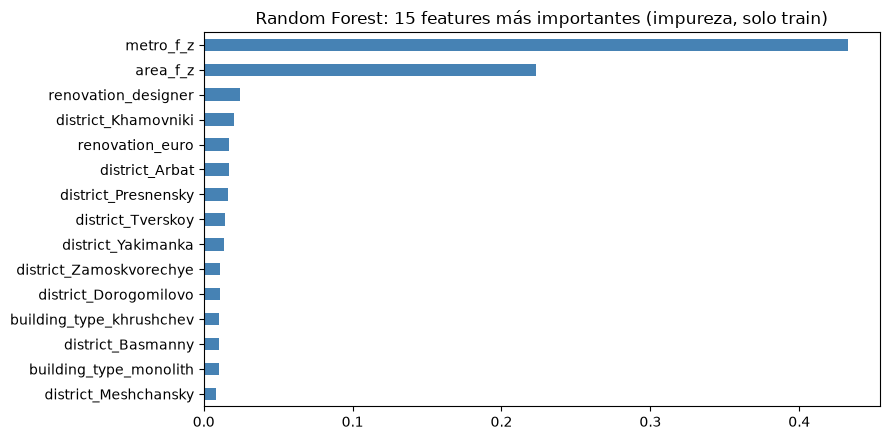

In [8]:
CONFIGS_RF = [(None, 1), (None, 5), (12, 1), (12, 5)]
filas_rf = []
for prof, hoja in CONFIGS_RF:
    def fp_rf(tr, va, prof=prof, hoja=hoja):
        m = RandomForestRegressor(n_estimators=300, max_depth=prof, min_samples_leaf=hoja,
                                  random_state=42, n_jobs=-1).fit(tr[FEATURES_BASE], tr[TARGET])
        return m.predict(va[FEATURES_BASE])
    _, rm, ma = walk_forward(fp_rf)
    filas_rf.append({"max_depth": str(prof), "min_samples_leaf": hoja, "RMSE_WF": rm, "MAE_WF": ma})
tabla_rf = pd.DataFrame(filas_rf)
print("Random Forest: configuraciones evaluadas por walk-forward dentro de train (n_estimators=300, random_state=42)")
display(tabla_rf.round(0))
ganadora_rf = tabla_rf.loc[tabla_rf["RMSE_WF"].idxmin()]
prof_g = None if ganadora_rf["max_depth"] == "None" else int(ganadora_rf["max_depth"])
hoja_g = int(ganadora_rf["min_samples_leaf"])

Xtr_full = train[FEATURES_BASE].astype(float)
rf_full = RandomForestRegressor(n_estimators=300, max_depth=prof_g, min_samples_leaf=hoja_g,
                                random_state=42, n_jobs=-1).fit(Xtr_full, yg)
importancias = pd.Series(rf_full.feature_importances_, index=FEATURES_BASE).sort_values(ascending=False)
tabla_importancias_rf = pd.DataFrame({"feature": importancias.index, "importancia": importancias.to_numpy()})
tabla_importancias_rf["importancia_acumulada"] = tabla_importancias_rf["importancia"].cumsum()
total_imp = float(tabla_importancias_rf["importancia"].sum())
if total_imp <= 0:
    cols_rf = []
else:
    # Prefijo mínimo del ranking cuya importancia acumulada alcanza el 90 % (incluye la feature que cruza el umbral).
    corte = int((tabla_importancias_rf["importancia_acumulada"] < 0.90 * total_imp).sum()) + 1
    corte = min(max(corte, 0), len(tabla_importancias_rf))
    cols_rf = sorted(tabla_importancias_rf.iloc[:corte]["feature"].tolist())
print(f"RF ganadora: max_depth={ganadora_rf['max_depth']}, min_samples_leaf={hoja_g} | RMSE walk-forward = {float(ganadora_rf['RMSE_WF']):,.0f} RUB")
print(f"Criterio de selección RF: prefijo mínimo del ranking con importancia acumulada >= 90% -> {len(cols_rf)} features.")
print(f"Features seleccionadas por RF ({len(cols_rf)}): {', '.join(cols_rf) if cols_rf else '(ninguna)'}")
display(tabla_importancias_rf.round(5))
fig_rf, ax = plt.subplots(figsize=(9, 4.5))
importancias.head(15).sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_title("Random Forest: 15 features más importantes (impureza, solo train)")
plt.tight_layout(); plt.show()

## 4. Modelos manuales basados en hipótesis (formulados antes de mirar test)

Los modelos manuales **no son selecciones automáticas**: son hipótesis de negocio o de vivienda escritas explícitamente en una estructura editable (`MANUALES`), usando únicamente features que ya existen en la matriz de la etapa 03, y se formulan **antes de evaluar test**. Ninguna lista manual se ajusta mirando resultados de test.

Hipótesis de cada caso:

- `Manual_superficie`: el tamaño de la vivienda es el primer determinante del alquiler; alcanza con la superficie transformada y estandarizada.
- `Manual_ubicacion`: la ubicación manda; alcanza con la distancia al metro y el distrito, sin características internas de la vivienda.
- `Manual_caracteristicas_vivienda`: lo que se paga es la vivienda en sí (superficie, tipo de edificio y renovación), sin ubicación fina.
- `Manual_superficie_ubicacion`: superficie más ubicación (metro y distrito) explican el grueso del precio, sin tipo de edificio ni renovación.
- `Manual_vivienda_ubicacion`: la hipótesis completa de vivienda más ubicación: superficie, metro, distrito, tipo de edificio, renovación, amueblado y mascotas. Como reúne todos los bloques de la matriz, puede coincidir exactamente con el OLS completo; esa equivalencia se detecta abajo y no se duplica el cálculo ni el run: queda registrado como alias.

La celda siguiente define los casos, valida que cada feature exista en la matriz y detecta duplicados exactos contra el OLS completo, contra los candidatos automáticos y entre manuales.

In [9]:
DISTRICT_COLS = [c for c in FEATURES_BASE if c.startswith("district_")]
BUILDING_COLS = [c for c in FEATURES_BASE if c.startswith("building_type_")]
RENOVATION_COLS = [c for c in FEATURES_BASE if c.startswith("renovation_")]

# Estructura editable: agregar o quitar features acá, antes de cualquier evaluación en test.
MANUALES = {
    "Manual_superficie": {
        "hipotesis": "El tamaño de la vivienda es el primer determinante del alquiler.",
        "cols": ["area_f_z"],
    },
    "Manual_ubicacion": {
        "hipotesis": "La ubicación (metro y distrito) manda sobre las características internas.",
        "cols": ["metro_f_z"] + DISTRICT_COLS,
    },
    "Manual_caracteristicas_vivienda": {
        "hipotesis": "Se paga la vivienda en sí: superficie, tipo de edificio y renovación, sin ubicación fina.",
        "cols": ["area_f_z"] + BUILDING_COLS + RENOVATION_COLS,
    },
    "Manual_superficie_ubicacion": {
        "hipotesis": "Superficie más ubicación explican el grueso del precio, sin tipo de edificio ni renovación.",
        "cols": ["area_f_z", "metro_f_z"] + DISTRICT_COLS,
    },
    "Manual_vivienda_ubicacion": {
        "hipotesis": "Vivienda completa más ubicación: superficie, metro, distrito, edificio, renovación, amueblado y mascotas.",
        "cols": ["area_f_z", "metro_f_z"] + DISTRICT_COLS + BUILDING_COLS + RENOVATION_COLS + ["furnished", "pets_allowed"],
    },
}

for _nombre, _caso in MANUALES.items():
    _faltantes = [c for c in _caso["cols"] if c not in FEATURES_BASE]
    assert not _faltantes, f"{_nombre} usa features fuera de la matriz de la etapa 03: {_faltantes}"
    assert len(_caso["cols"]) == len(set(_caso["cols"])), f"{_nombre} tiene features repetidas"

# Detección de alias: una lista manual que duplica exactamente otro candidato no se recalcula ni se duplica en MLflow.
_candidatos_previos = {"OLS_completo": list(FEATURES_BASE), "BSS_okrug": list(bss_okrug["cols"]),
                       "BSS_precio_venta": list(bss_precio["cols"]), "SWS": list(sws["cols"]),
                       "OLS_desde_Lasso": list(cols_lasso), "OLS_desde_RF": list(cols_rf)}
ALIAS_MANUALES = {}
for _nombre, _caso in MANUALES.items():
    _set = frozenset(_caso["cols"])
    for _otro, _cols_otro in {**_candidatos_previos, **{k: v["cols"] for k, v in list(MANUALES.items())[:list(MANUALES).index(_nombre)]}}.items():
        if frozenset(_cols_otro) == _set:
            ALIAS_MANUALES[_nombre] = _otro
            break

for _nombre, _caso in MANUALES.items():
    _alias = f" | ALIAS de {_otro} (mismo conjunto exacto: no se duplica cálculo ni run)" if (_otro := ALIAS_MANUALES.get(_nombre)) else ""
    print(f"{_nombre} ({len(_caso['cols'])} features): {_caso['hipotesis']}{_alias}")
    print(f"  features: {', '.join(_caso['cols'])}")
if ALIAS_MANUALES:
    print(f"Alias detectados: {ALIAS_MANUALES}")
else:
    print("Sin alias: ningún manual duplica exactamente a otro candidato.")

Manual_superficie (1 features): El tamaño de la vivienda es el primer determinante del alquiler.
  features: area_f_z
Manual_ubicacion (129 features): La ubicación (metro y distrito) manda sobre las características internas.
  features: metro_f_z, district_Aeroport, district_Akademichesky, district_Alekseevsky, district_Altufyevsky, district_Arbat, district_Babushkinsky, district_Basmanny, district_Begovoy, district_Beskudnikovsky, district_Bibirevo, district_Biryulyovo Vostochnoye, district_Biryulyovo Zapadnoye, district_Bogorodskoye, district_Brateyevo, district_Butyrsky, district_Chertanovo Severnoye, district_Chertanovo Tsentralnoye, district_Chertanovo Yuzhnoye, district_Cheryomushki, district_Danilovsky, district_Desyonovskoye, district_Dmitrovsky, district_Donskoy, district_Dorogomilovo, district_Fili-Davydkovo, district_Filimonkovskoye, district_Filyovsky Park, district_Gagarinsky, district_Golovinsky, district_Golyanovo, district_Ivanovskoye, district_Izmaylovo, district_Khamo

## 5. Reajuste OLS de los subconjuntos seleccionados

Cada subconjunto seleccionado por BSS, Stepwise, Lasso o Random Forest se reajusta como un **OLS común ajustado en train** con ese subconjunto, para obtener una comparación estadística homogénea. Los baselines OLS y cada modelo manual (no alias) también entran como OLS. Si un selector devuelve una lista vacía, el OLS reajustado es un modelo solo con intercepto y se reporta como tal, sin romper la comparación.

Los predictores nativos (Lasso con su pipeline y Random Forest) se conservan aparte, con sus propias predicciones: sus estadísticos clásicos (AIC, BIC, F, R² ajustado) no tienen la misma interpretación y se reportan como no aplicables; la comparación estadística común se hace con el OLS reajustado correspondiente.

In [10]:
# Candidatos OLS comparables: baselines + reajustes de cada selector + manuales sin duplicar alias.
candidatos_ols_todos = {
    "OLS_completo": list(FEATURES_BASE),
    "BSS_okrug": list(bss_okrug["cols"]),
    "BSS_precio_venta": list(bss_precio["cols"]),
    "SWS": list(sws["cols"]),
    "OLS_desde_Lasso": list(cols_lasso),
    "OLS_desde_RF": list(cols_rf),
}
for _nombre, _caso in MANUALES.items():
    if _nombre in ALIAS_MANUALES:
        print(f"{_nombre}: alias de {ALIAS_MANUALES[_nombre]}; se reutiliza ese OLS y no se duplica.")
    else:
        candidatos_ols_todos[_nombre] = list(_caso["cols"])

# Alias entre automáticos/baselines también se explicitan (conservando el primer nombre como canónico).
_vistos = {}
ALIAS_OLS = {}
candidatos_ols = {}
for _nombre, _cols in candidatos_ols_todos.items():
    _clave = frozenset(_cols)
    if _clave in _vistos:
        ALIAS_OLS[_nombre] = _vistos[_clave]
        print(f"{_nombre}: alias exacto de {_vistos[_clave]}; no se duplica el ajuste.")
    else:
        _vistos[_clave] = _nombre
        candidatos_ols[_nombre] = _cols
print(f"Candidatos OLS únicos a ajustar: {list(candidatos_ols)}")
for _n, _c in candidatos_ols.items():
    print(f"  {_n}: {len(_c)} features")

Manual_vivienda_ubicacion: alias de OLS_completo; se reutiliza ese OLS y no se duplica.
BSS_okrug: alias exacto de OLS_completo; no se duplica el ajuste.
BSS_precio_venta: alias exacto de OLS_completo; no se duplica el ajuste.
OLS_desde_Lasso: alias exacto de OLS_completo; no se duplica el ajuste.
Candidatos OLS únicos a ajustar: ['OLS_completo', 'SWS', 'OLS_desde_RF', 'Manual_superficie', 'Manual_ubicacion', 'Manual_caracteristicas_vivienda', 'Manual_superficie_ubicacion']
  OLS_completo: 140 features
  SWS: 109 features
  OLS_desde_RF: 25 features
  Manual_superficie: 1 features
  Manual_ubicacion: 129 features
  Manual_caracteristicas_vivienda: 9 features
  Manual_superficie_ubicacion: 130 features


## 6. Comparación uniforme de modelos y features

La comparación separa dos planos que no deben mezclarse:

1. **Predictores nativos:** Lasso (pipeline escalado) y Random Forest, evaluados con sus propias predicciones en train, validación temporal walk-forward dentro de train y test. Para estos modelos, AIC, BIC, F y R² ajustado se muestran como **no aplicables**.
2. **Modelos OLS comparables:** un OLS ajustado en train con cada subconjunto (BSS, Stepwise, Lasso, Random Forest, manuales y baselines OLS), con sus estadísticas clásicas de train y sus métricas de predicción en train, validación temporal y test.

Para cada predictor se reportan R², RMSE en rublos y MAE en rublos. Para cada OLS se reportan además R² y R² ajustado de train, F y p-valor del test F global, AIC, BIC, log-likelihood, número de observaciones y número de features aclarando si incluye el intercepto. La validación temporal de los OLS reajustados reajusta el OLS por fold con el subconjunto ya elegido en todo train, por lo que es descriptiva del subconjunto y no una selección adicional.

Las tablas completas (resumen, features por candidato, coeficientes por OLS, coeficientes de Lasso e importancias de Random Forest) se muestran abajo y se registran como artefactos en MLflow.

In [11]:
# ---------- Predictores nativos: Lasso y Random Forest con sus propias predicciones ----------
def metricas_tres_planos(pred_train, wf_rmse, wf_mae, wf_r2, pred_test):
    return {"R2_train": metricas_pred(train[TARGET], pred_train)["R2"],
            "RMSE_RUB_train": metricas_pred(train[TARGET], pred_train)["RMSE_RUB"],
            "MAE_RUB_train": metricas_pred(train[TARGET], pred_train)["MAE_RUB"],
            "R2_validacion": wf_r2, "RMSE_RUB_validacion": wf_rmse, "MAE_RUB_validacion": wf_mae,
            **{f"{k}_test": v for k, v in metricas_pred(test[TARGET], pred_test).items()}}

# Lasso nativo: walk-forward ya calculado por fracción; se recupera el promedio de la fracción elegida.
_fila_lasso_wf = resumen_lasso.loc[resumen_lasso["fraccion"] == FRAC_LASSO_ELEGIDA].iloc[0]
pred_lasso_train = lasso_pipe.predict(train[FEATURES_BASE])
pred_lasso_test = lasso_pipe.predict(test[FEATURES_BASE])
# RF nativo: walk-forward de la configuración ganadora.
def _fp_rf_ganadora(tr, va):
    m = RandomForestRegressor(n_estimators=300, max_depth=prof_g, min_samples_leaf=hoja_g,
                              random_state=42, n_jobs=-1).fit(tr[FEATURES_BASE], tr[TARGET])
    return m.predict(va[FEATURES_BASE])
_tabla_wf_rf, _rmse_wf_rf, _mae_wf_rf = walk_forward(_fp_rf_ganadora)
_r2_wf_rf = float(_tabla_wf_rf["R2"].mean()) if not _tabla_wf_rf.empty else np.nan
pred_rf_train = rf_full.predict(train[FEATURES_BASE])
pred_rf_test = rf_full.predict(test[FEATURES_BASE])

filas_nativos = [
    {"modelo": "Lasso_nativo", "metodo": "Lasso", "tipo": "predictor nativo", "n_features": len(cols_lasso), "n_features_entrada": len(FEATURES_BASE), "n_features_seleccionadas_para_OLS": len(cols_lasso),
     **metricas_tres_planos(pred_lasso_train, float(_fila_lasso_wf["RMSE_WF"]), float(_fila_lasso_wf["MAE_WF"]), float(_fila_lasso_wf["R2_WF"]), pred_lasso_test)},
    {"modelo": "RandomForest_nativo", "metodo": "Random Forest", "tipo": "predictor nativo", "n_features": len(FEATURES_BASE), "n_features_entrada": len(FEATURES_BASE), "n_features_seleccionadas_para_OLS": len(cols_rf),
     **metricas_tres_planos(pred_rf_train, _rmse_wf_rf, _mae_wf_rf, _r2_wf_rf, pred_rf_test)},
    {"modelo": "Baseline_ingenuo", "metodo": "mediana_train", "tipo": "predictor nativo", "n_features": 0, "n_features_entrada": 0, "n_features_seleccionadas_para_OLS": 0,
     "R2_train": m_naive_train["R2"], "RMSE_RUB_train": m_naive_train["RMSE_RUB"], "MAE_RUB_train": m_naive_train["MAE_RUB"],
     "R2_validacion": float(tabla_wf_naive["R2"].mean()) if not tabla_wf_naive.empty else np.nan,
     "RMSE_RUB_validacion": rmse_wf_naive, "MAE_RUB_validacion": mae_wf_naive,
     **{f"{k}_test": v for k, v in m_naive_test.items()}},
]
tabla_nativos = pd.DataFrame(filas_nativos)
print("Predictores nativos (AIC/BIC/F/R² ajustado: no aplicables a estos estimadores; ver OLS reajustados)")
display(tabla_nativos.round(2))

# ---------- OLS comparables: estadísticas de train + predicción en train / validación / test ----------
METODO_OLS = {"OLS_completo": "OLS completo (baseline)", "BSS_okrug": "BSS agrupado por okrug",
              "BSS_precio_venta": "BSS agrupado por precio de venta", "SWS": "Stepwise forward con BIC",
              "OLS_desde_Lasso": "Lasso (selector)", "OLS_desde_RF": "Random Forest (selector)"}
def _tipo_ols(nombre):
    if nombre == "OLS_completo":
        return "OLS baseline"
    if nombre.startswith("Manual_"):
        return "OLS manual"
    return "OLS reajustado desde selector"

modelos_ols = {}
filas_ols = []
for nombre, cols_c in candidatos_ols.items():
    m_c = fit_ols(cols_c)
    modelos_ols[nombre] = m_c
    est = estadisticas_ols(m_c, cols_c)
    met_tr = metricas_pred(train[TARGET], predict_ols(m_c, cols_c, train))
    met_wf, _tabla_wf_c = metricas_wf_ols(cols_c)
    met_te = metricas_pred(test[TARGET], predict_ols(m_c, cols_c, test))
    filas_ols.append({"modelo": nombre, "metodo": METODO_OLS.get(nombre, "Manual (hipótesis previa)" if nombre.startswith("Manual_") else nombre), "tipo": _tipo_ols(nombre),
                      "n_features_sin_intercepto": len(cols_c), "n_parametros_con_intercepto": len(cols_c) + 1,
                      "n_obs_train": est["n_obs"],
                      "R2_train": est["R2_train"], "Adj_R2_train": est["Adj_R2_train"],
                      "F_train": est["F"], "F_pvalor_train": est["F_pvalor"],
                      "AIC_train": est["AIC"], "BIC_train": est["BIC"], "LogLik_train": est["LogLik"],
                      "RMSE_RUB_train": met_tr["RMSE_RUB"], "MAE_RUB_train": met_tr["MAE_RUB"],
                      "R2_validacion": met_wf["R2"], "RMSE_RUB_validacion": met_wf["RMSE_RUB"], "MAE_RUB_validacion": met_wf["MAE_RUB"],
                      "R2_test": met_te["R2"], "RMSE_RUB_test": met_te["RMSE_RUB"], "MAE_RUB_test": met_te["MAE_RUB"]})
tabla_ols = pd.DataFrame(filas_ols).sort_values("RMSE_RUB_test")
print("Modelos OLS comparables (estadísticas clásicas calculadas en train; predicción en train, validación temporal y test)")
display(tabla_ols.round(2))

# ---------- Tabla resumen: una fila por candidato (nativos con estadísticos OLS como no aplicables) ----------
filas_resumen = []
for _, r in tabla_nativos.iterrows():
    filas_resumen.append({"modelo": r["modelo"], "metodo": r["metodo"], "tipo": r["tipo"],
                          "n_features": int(r["n_features"]), "R2_test": r["R2_test"],
                          "Adj_R2_train": np.nan, "F_train": np.nan, "F_pvalor_train": np.nan,
                          "AIC_train": np.nan, "BIC_train": np.nan,
                          "RMSE_RUB_test": r["RMSE_RUB_test"], "MAE_RUB_test": r["MAE_RUB_test"]})
for _, r in tabla_ols.iterrows():
    filas_resumen.append({"modelo": r["modelo"], "metodo": r["metodo"], "tipo": r["tipo"],
                          "n_features": int(r["n_features_sin_intercepto"]), "R2_test": r["R2_test"],
                          "Adj_R2_train": r["Adj_R2_train"], "F_train": r["F_train"], "F_pvalor_train": r["F_pvalor_train"],
                          "AIC_train": r["AIC_train"], "BIC_train": r["BIC_train"],
                          "RMSE_RUB_test": r["RMSE_RUB_test"], "MAE_RUB_test": r["MAE_RUB_test"]})
# Alias manuales/automáticos: fila explícita que apunta al canónico, sin recalcular métricas.
_metodos_alias = {**{k: k for k in candidatos_ols}, **ALIAS_OLS}
for _alias, _canon in {**ALIAS_OLS, **{k: v for k, v in ALIAS_MANUALES.items()}}.items():
    if _alias in [f["modelo"] for f in filas_resumen]:
        continue
    _base = next((f for f in filas_resumen if f["modelo"] == _canon), None)
    if _base is not None:
        filas_resumen.append({**_base, "modelo": _alias, "metodo": _alias, "tipo": f"alias de {_canon} (mismo conjunto exacto)"})
tabla_resumen = pd.DataFrame(filas_resumen).sort_values("RMSE_RUB_test")
print("Tabla resumen (una fila por candidato; en nativos, Adj_R2/F/AIC/BIC figuran como no aplicables = NaN)")
display(tabla_resumen.round(2))

# ---------- Tabla larga de features por candidato (sin limitarse al conteo) ----------
filas_largas = []
_todos_los_candidatos = {**candidatos_ols,
                         **{k: list(v["cols"]) for k, v in MANUALES.items()},
                         "Lasso_nativo": list(cols_lasso), "RandomForest_nativo": list(cols_rf)}
for nombre, cols_c in _todos_los_candidatos.items():
    if len(cols_c) == 0:
        filas_largas.append({"modelo": nombre, "orden": 0, "feature": "(sin features: solo intercepto o mediana)"})
    for i, c in enumerate(cols_c, start=1):
        filas_largas.append({"modelo": nombre, "orden": i, "feature": c})
tabla_features_larga = pd.DataFrame(filas_largas)
print(f"Tabla larga de features: {len(tabla_features_larga):,} filas (modelo, orden, feature)")
display(tabla_features_larga.head(30))

# ---------- Coeficientes por OLS + coeficientes Lasso + importancias RF ----------
coef_por_ols = {nombre: tabla_coeficientes(m) for nombre, m in modelos_ols.items()}
tabla_coef_todos_ols = pd.concat([df.assign(modelo=nombre) for nombre, df in coef_por_ols.items()], ignore_index=True)[
    ["modelo", "feature", "coef", "std_err", "t", "p_valor", "IC95_inf", "IC95_sup"]]
print("Coeficientes de todos los OLS (feature, coeficiente, error estándar, t, p-valor, IC 95%; lectura descriptiva post-selección)")
display(tabla_coef_todos_ols.round(3).head(40))
print("Coeficientes de Lasso asociados a cada feature (escala estandarizada y rublos por unidad original):")
display(tabla_coef_lasso.round(4))
print("Importancias de Random Forest asociadas a cada feature (impureza, solo train):")
display(tabla_importancias_rf.round(5))

Predictores nativos (AIC/BIC/F/R² ajustado: no aplicables a estos estimadores; ver OLS reajustados)


,modelo,metodo,tipo,n_features,n_features_entrada,n_features_seleccionadas_para_OLS,R2_train,RMSE_RUB_train,MAE_RUB_train,R2_validacion,RMSE_RUB_validacion,MAE_RUB_validacion,R2_test,RMSE_RUB_test,MAE_RUB_test
0,Lasso_nativo,Lasso,predictor nativo,140,140,140,0.90,7796.79,6068.99,0.88,8702.15,6652.13,0.81,13587.95,7742.32
1,RandomForest_nativo,Random Forest,predictor nativo,140,140,25,0.98,3719.52,2714.52,0.76,12017.59,8642.91,0.72,16554.01,9603.80
2,Baseline_ingenuo,mediana_train,predictor nativo,0,0,0,-0.04,25113.03,19065.07,-0.16,26616.45,19779.95,-0.11,32951.27,22261.81


Modelos OLS comparables (estadísticas clásicas calculadas en train; predicción en train, validación temporal y test)


,modelo,metodo,tipo,n_features_sin_intercepto,n_parametros_con_intercepto,n_obs_train,R2_train,Adj_R2_train,F_train,F_pvalor_train,AIC_train,BIC_train,LogLik_train,RMSE_RUB_train,MAE_RUB_train,R2_validacion,RMSE_RUB_validacion,MAE_RUB_validacion,R2_test,RMSE_RUB_test,MAE_RUB_test
0,OLS_completo,OLS completo (baseline),OLS baseline,140,141,14820,0.90,0.90,941.12,0.0,307954.92,309027.04,-153836.46,7796.18,6068.91,0.88,8698.66,6650.96,0.81,13583.92,7741.19
1,SWS,Stepwise forward con BIC,OLS reajustado desde selector,109,110,14820,0.90,0.90,1165.01,0.0,308411.83,309248.24,-154095.91,7933.87,6170.92,0.87,8809.83,6696.87,0.81,13653.18,7802.50
2,OLS_desde_RF,Random Forest (selector),OLS reajustado desde selector,25,26,14820,0.80,0.80,2385.28,0.0,317870.46,318068.16,-158909.23,10978.36,8635.65,0.78,11735.87,9086.56,0.74,16073.12,10799.52
6,Manual_superficie_ubicacion,Manual (hipótesis previa),OLS manual,130,131,14820,0.82,0.82,505.70,0.0,316825.02,317821.11,-158281.51,10523.07,8142.02,0.79,11396.26,8606.34,0.73,16097.60,10023.39
4,Manual_ubicacion,Manual (hipótesis previa),OLS manual,129,130,14820,0.65,0.64,206.96,0.0,326670.32,327658.80,-163205.16,14669.93,11304.88,0.60,15560.81,11634.77,0.57,20422.67,13599.21
5,Manual_caracteristicas_vivienda,Manual (hipótesis previa),OLS manual,9,10,14820,0.26,0.26,566.79,0.0,337395.02,337471.06,-168687.51,21236.67,16233.60,0.22,21841.75,15984.42,0.20,27882.74,18540.11
3,Manual_superficie,Manual (hipótesis previa),OLS manual,1,2,14820,0.18,0.18,3283.65,0.0,338799.02,338814.23,-169397.51,22278.84,17262.49,0.14,22908.82,17047.60,0.14,29049.26,19587.51


Tabla resumen (una fila por candidato; en nativos, Adj_R2/F/AIC/BIC figuran como no aplicables = NaN)


...

,modelo,feature,coef,std_err,t,p_valor,IC95_inf,IC95_sup
0,OLS_completo,const,48721.756,689.220,70.691,0.000,47370.798,50072.714
1,OLS_completo,area_f_z,10243.779,64.620,158.524,0.000,10117.117,10370.442
2,OLS_completo,metro_f_z,-6706.526,108.930,-61.567,0.000,-6920.042,-6493.010
3,OLS_completo,furnished,3516.396,141.682,24.819,0.000,3238.681,3794.110
4,OLS_completo,pets_allowed,-1214.531,140.529,-8.643,0.000,-1489.986,-939.076
5,OLS_completo,district_Aeroport,-4825.714,1018.407,-4.738,0.000,-6821.920,-2829.508
6,OLS_completo,district_Akademichesky,7072.142,1007.310,7.021,0.000,5097.687,9046.597
7,OLS_completo,district_Alekseevsky,-6458.181,1029.256,-6.275,0.000,-8475.651,-4440.711
8,OLS_completo,district_Altufyevsky,-15227.411,977.951,-15.571,0.000,-17144.318,-13310.504
9,OLS_completo,district_Arbat,35479.845,980.945,36.169,0.000,33557.070,37402.621


Coeficientes de Lasso asociados a cada feature (escala estandarizada y rublos por unidad original):


,feature,coef_estandarizado,coef_RUB_por_unidad_original,abs_coef_estandarizado
0,area_f_z,10242.2380,10242.2380,10242.2380
1,metro_f_z,-6718.9583,-6718.9583,6718.9583
137,renovation_designer,4375.0705,14484.1970,4375.0705
36,district_Khamovniki,3446.6655,41093.4459,3446.6655
8,district_Arbat,3279.0556,36438.4929,3279.0556
...,...,...,...,...
49,district_Kuntsevo,141.6693,1765.9379,141.6693
66,district_Mozhaysky,-136.5783,-1628.3772,136.5783
26,district_Donskoy,-103.7512,-1112.6500,103.7512
45,district_Kotlovka,94.1958,991.4618,94.1958


Importancias de Random Forest asociadas a cada feature (impureza, solo train):


,feature,importancia,importancia_acumulada
0,metro_f_z,0.43260,0.43260
1,area_f_z,0.22322,0.65582
2,renovation_designer,0.02450,0.68032
3,district_Khamovniki,0.02022,0.70055
4,renovation_euro,0.01719,0.71773
...,...,...,...
135,district_Novofyodorovskoye,0.00002,0.99994
136,district_Voronovskoye,0.00002,0.99996
137,district_Klyonovskoye,0.00002,0.99997
138,district_Rogovskoye,0.00001,0.99999


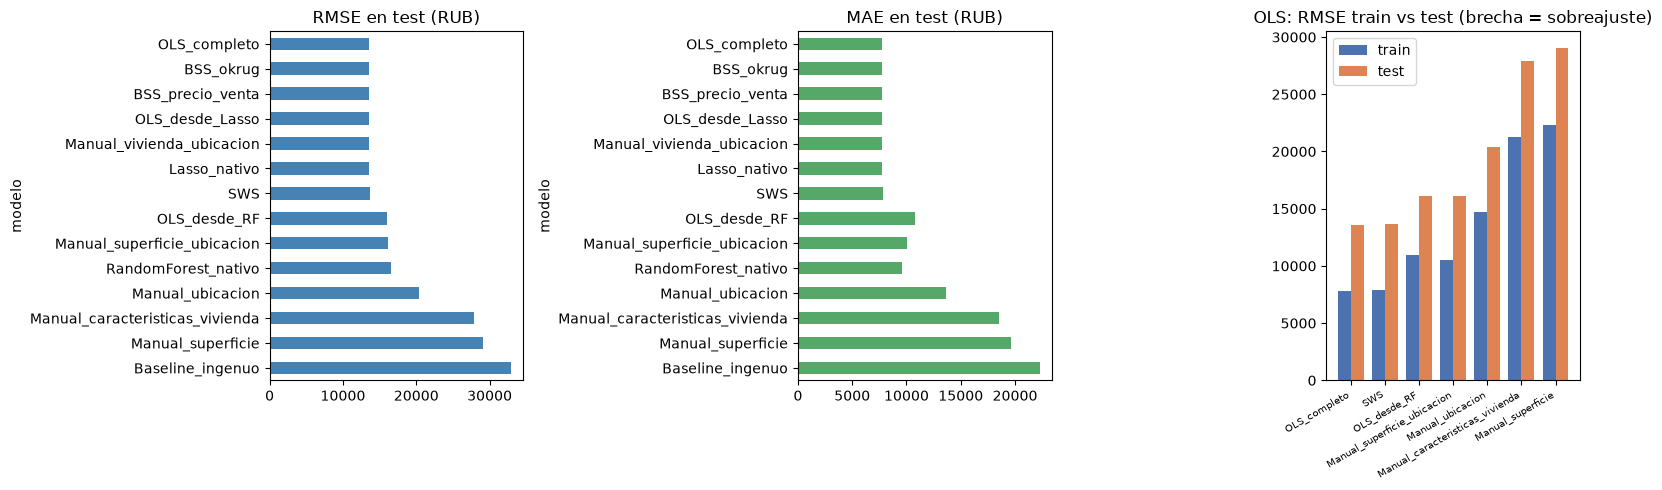

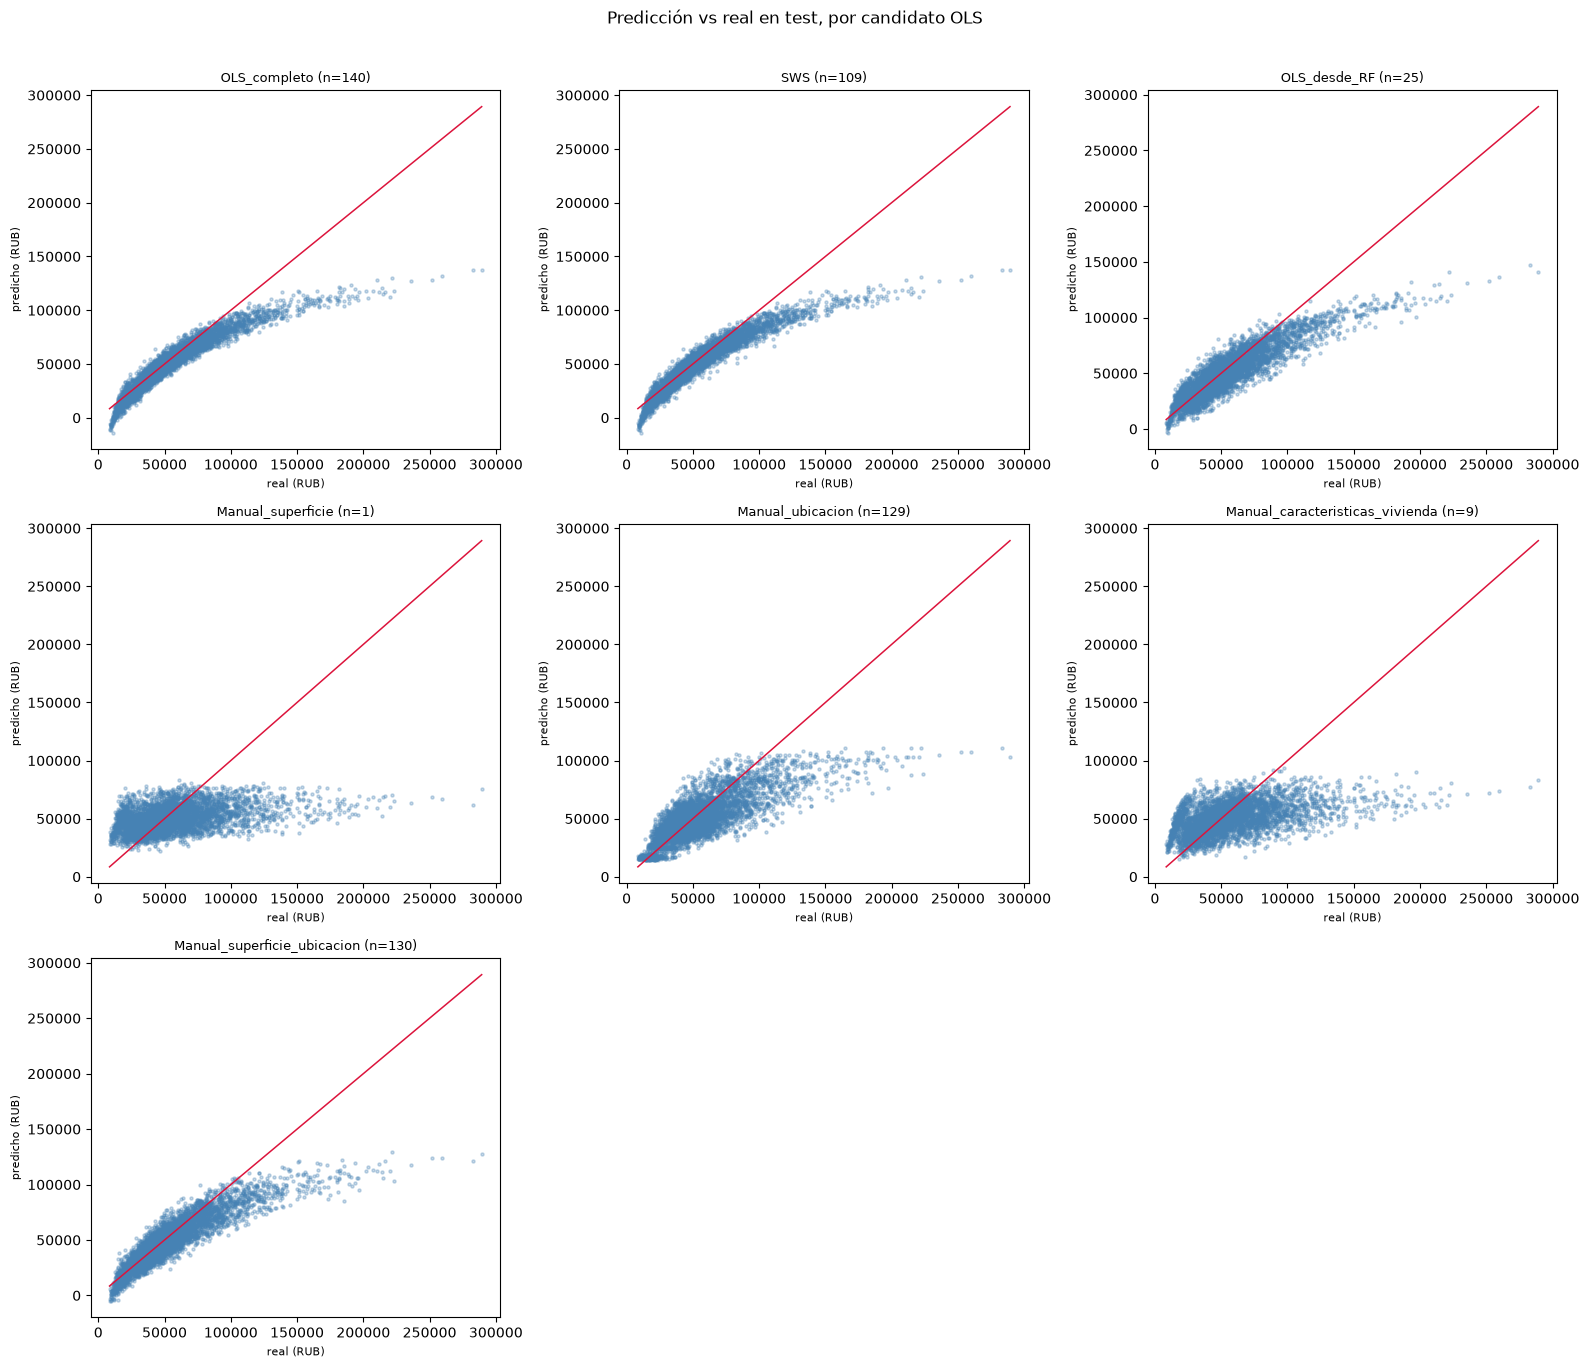

In [12]:
# Gráficos de comparación uniforme (test ordenado, MAE, brecha train-test y predicción vs. real por OLS)
tc = tabla_resumen.sort_values("RMSE_RUB_test")
fig_comp, axes = plt.subplots(1, 3, figsize=(16, 5))
tc.set_index("modelo")["RMSE_RUB_test"].plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("RMSE en test (RUB)"); axes[0].invert_yaxis()
tc.set_index("modelo")["MAE_RUB_test"].plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("MAE en test (RUB)"); axes[1].invert_yaxis()
sel = tabla_ols.copy()
x = np.arange(len(sel)); w = 0.38
axes[2].bar(x - w / 2, sel["RMSE_RUB_train"], width=w, label="train", color="#4C72B0")
axes[2].bar(x + w / 2, sel["RMSE_RUB_test"], width=w, label="test", color="#DD8452")
axes[2].set_xticks(x); axes[2].set_xticklabels(sel["modelo"], rotation=30, ha="right", fontsize=7)
axes[2].set_title("OLS: RMSE train vs test (brecha = sobreajuste)"); axes[2].legend()
plt.tight_layout(); plt.show()

n_ols = len(candidatos_ols)
cols_fig = 3
rows_fig = int(np.ceil(n_ols / cols_fig)) if n_ols else 1
fig_pred, axes_pred = plt.subplots(rows_fig, cols_fig, figsize=(16, 4.5 * rows_fig), squeeze=False)
for ax, (nombre, cols_c) in zip(axes_pred.ravel(), candidatos_ols.items()):
    m_c = modelos_ols[nombre]
    p_te = predict_ols(m_c, cols_c, test)
    ax.scatter(test[TARGET], p_te, s=5, alpha=0.3, color="steelblue")
    lim = [float(test[TARGET].min()), float(test[TARGET].max())]
    ax.plot(lim, lim, color="crimson", lw=1.1)
    ax.set_title(f"{nombre} (n={len(cols_c)})", fontsize=9)
    ax.set_xlabel("real (RUB)", fontsize=8); ax.set_ylabel("predicho (RUB)", fontsize=8)
for ax in axes_pred.ravel()[n_ols:]:
    ax.axis("off")
fig_pred.suptitle("Predicción vs real en test, por candidato OLS", y=1.01)
plt.tight_layout(); plt.show()

,modelo,n_features,district,building_type,renovation,continuas_binarias,RMSE_RUB_test
0,OLS_completo,140,128,5,3,4,13584.0
1,SWS,109,97,5,3,4,13653.0
2,OLS_desde_RF,25,16,4,2,3,16073.0
6,Manual_superficie_ubicacion,130,128,0,0,2,16098.0
4,Manual_ubicacion,129,128,0,0,1,20423.0
5,Manual_caracteristicas_vivienda,9,0,5,3,1,27883.0
3,Manual_superficie,1,0,0,0,1,29049.0



OLS_completo (140): area_f_z, metro_f_z, furnished, pets_allowed, district_Aeroport, district_Akademichesky, district_Alekseevsky, district_Altufyevsky, district_Arbat, district_Babushkinsky, district_Basmanny, district_Begovoy, district_Beskudnikovsky, district_Bibirevo, district_Biryulyovo Vostochnoye, district_Biryulyovo Zapadnoye, district_Bogorodskoye, district_Brateyevo, district_Butyrsky, district_Chertanovo Severnoye, district_Chertanovo Tsentralnoye, district_Chertanovo Yuzhnoye, district_Cheryomushki, district_Danilovsky, district_Desyonovskoye, district_Dmitrovsky, district_Donskoy, district_Dorogomilovo, district_Fili-Davydkovo, district_Filimonkovskoye, district_Filyovsky Park, district_Gagarinsky, district_Golovinsky, district_Golyanovo, district_Ivanovskoye, district_Izmaylovo, district_Khamovniki, district_Khoroshyovsky, district_Khovrino, district_Kievsky, district_Klyonovskoye, district_Kokoshkino, district_Konkovo, district_Koptevo, district_Kosino-Ukhtomsky, distri

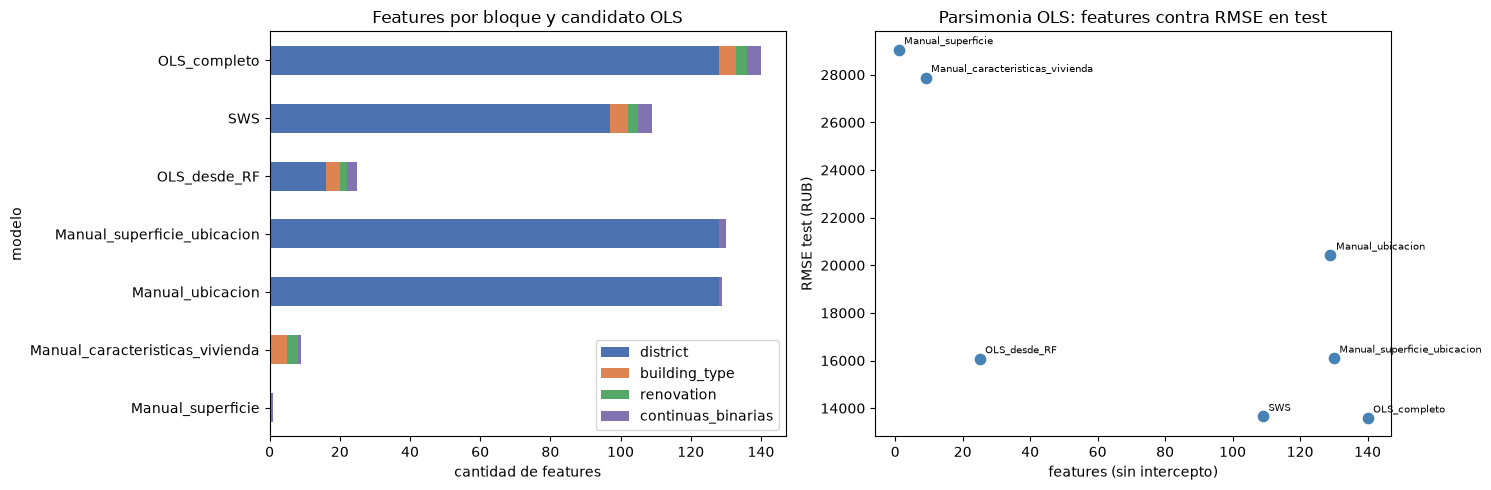

In [13]:
# Qué features usa cada candidato: conteo por bloque, listas exactas y mapa de parsimonia en test
conteo = []
for nombre, cols_c in candidatos_ols.items():
    fila = {"modelo": nombre, "n_features": len(cols_c)}
    for b in ["district", "building_type", "renovation", "continuas_binarias"]:
        fila[b] = sum(1 for c in cols_c if bloque_de(c) == b)
    rmse_f = float(tabla_ols.loc[tabla_ols["modelo"] == nombre, "RMSE_RUB_test"].iloc[0])
    fila["RMSE_RUB_test"] = round(rmse_f, 0)
    conteo.append(fila)
tabla_features = pd.DataFrame(conteo).sort_values("RMSE_RUB_test")
display(tabla_features)
for nombre, cols_c in _todos_los_candidatos.items():
    print(f"\n{nombre} ({len(cols_c)}): {', '.join(cols_c) if cols_c else '(sin features)'}")
if ALIAS_MANUALES or ALIAS_OLS:
    print(f"\nAlias exactos (sin duplicar ajuste): manuales={ALIAS_MANUALES} | OLS={ALIAS_OLS}")

fig_par, axes_par = plt.subplots(1, 2, figsize=(15, 5))
tf = tabla_features.set_index("modelo")
tf[["district", "building_type", "renovation", "continuas_binarias"]].plot.barh(
    stacked=True, ax=axes_par[0], color=["#4C72B0", "#DD8452", "#55A868", "#8172B2"])
axes_par[0].set_title("Features por bloque y candidato OLS"); axes_par[0].set_xlabel("cantidad de features")
axes_par[0].invert_yaxis()
axes_par[1].scatter(tabla_ols["n_features_sin_intercepto"], tabla_ols["RMSE_RUB_test"], color="steelblue", s=55, zorder=3)
for _, r_ in tabla_ols.iterrows():
    axes_par[1].annotate(str(r_["modelo"]), (r_["n_features_sin_intercepto"], r_["RMSE_RUB_test"]),
                         textcoords="offset points", xytext=(4, 4), fontsize=7)
axes_par[1].set_title("Parsimonia OLS: features contra RMSE en test")
axes_par[1].set_xlabel("features (sin intercepto)"); axes_par[1].set_ylabel("RMSE test (RUB)")
plt.tight_layout(); plt.show()

### Elección del modelo final: regla de parsimonia del 1 % en test

Se conserva la regla vigente del notebook: entre los **candidatos OLS comparables** (baselines OLS, reajustes de BSS, Stepwise, Lasso y Random Forest, y manuales no alias), gana el OLS **más chico cuyo RMSE en test quede dentro del 1 % del mejor RMSE en test**. Los predictores nativos no compiten por este título porque el modelo final buscado es un OLS interpretable; se reportan como referencia predictiva.

- **Elegibles:** todos los OLS únicos de `candidatos_ols`, incluidos los manuales no alias. Los alias heredan el resultado de su canónico y no se ajustan dos veces.
- **Regla:** `elegible si RMSE_test <= 1,01 × mejor_RMSE_test_entre_OLS`; entre los elegibles, el de menor cantidad de features; desempate por menor RMSE en test.
- **Limitación ya declarada:** como la regla mira test para elegir, **test se usa también para elegir el modelo**. El RMSE en test del ganador queda sesgado a favor por selección y no debe leerse como evaluación final independiente. Ninguna feature manual, ningún `alpha` ni ningún hiperparámetro se eligió mirando test: solo esta elección final entre OLS ya cerrados usa test, y se declara como tal.

In [14]:
solo_ols = tabla_ols.copy()
mejor_rmse = float(solo_ols["RMSE_RUB_test"].min())
banda = mejor_rmse * 1.01
solo_ols["en_banda_1pct"] = solo_ols["RMSE_RUB_test"] <= banda
elegibles = solo_ols[solo_ols["en_banda_1pct"]].sort_values(["n_features_sin_intercepto", "RMSE_RUB_test"])
print(f"Mejor RMSE en test entre OLS: {mejor_rmse:,.0f} RUB | banda del 1%: hasta {banda:,.0f} RUB")
print("Candidatos OLS elegibles dentro de la banda (ordenados por parsimonia):")
display(elegibles[["modelo", "n_features_sin_intercepto", "RMSE_RUB_test", "MAE_RUB_test", "R2_test", "en_banda_1pct"]].round(2))
fila_final = elegibles.iloc[0]
FINAL_NOMBRE = str(fila_final["modelo"])
FINAL_COLS = list(candidatos_ols[FINAL_NOMBRE])
print(f"MODELO FINAL: {FINAL_NOMBRE} con {len(FINAL_COLS)} features (sin intercepto); RMSE test = {float(fila_final['RMSE_RUB_test']):,.0f} RUB dentro de la banda del 1%.")
print("Advertencia: test se usó para comparar y para elegir con esta regla; el RMSE del ganador no es una evaluación final independiente.")
print(f"Features exactas del modelo final ({len(FINAL_COLS)}): {', '.join(FINAL_COLS) if FINAL_COLS else '(solo intercepto)'}")
modelo_final = modelos_ols[FINAL_NOMBRE]
pred_final_test = predict_ols(modelo_final, FINAL_COLS, test)
metricas_final_test = metricas_pred(test[TARGET], pred_final_test)
print("Métricas del final en test (las mismas que entraron a la comparación y a la elección):",
      {k: round(v, 3) for k, v in metricas_final_test.items()})

Mejor RMSE en test entre OLS: 13,584 RUB | banda del 1%: hasta 13,720 RUB
Candidatos OLS elegibles dentro de la banda (ordenados por parsimonia):


,modelo,n_features_sin_intercepto,RMSE_RUB_test,MAE_RUB_test,R2_test,en_banda_1pct
1,SWS,109,13653.18,7802.50,0.81,True
0,OLS_completo,140,13583.92,7741.19,0.81,True


MODELO FINAL: SWS con 109 features (sin intercepto); RMSE test = 13,653 RUB dentro de la banda del 1%.
Advertencia: test se usó para comparar y para elegir con esta regla; el RMSE del ganador no es una evaluación final independiente.
Features exactas del modelo final (109): metro_f_z, area_f_z, renovation_designer, district_Khamovniki, renovation_euro, district_Arbat, district_Tverskoy, district_Presnensky, district_Yakimanka, building_type_khrushchev, district_Zamoskvorechye, district_Dorogomilovo, district_Basmanny, district_Meshchansky, district_Krasnoselsky, district_Tagansky, district_Krylatskoye, district_Prospekt Vernadskogo, district_Lomonosovsky, district_Gagarinsky, district_Ramenki, building_type_stalin, building_type_monolith, building_type_brick, district_Filyovsky Park, district_Troparyovo-Nikulino, furnished, district_Kurkino, district_Akademichesky, district_Fili-Davydkovo, renovation_no_renovation, building_type_modern_panel, district_Khoroshyovsky, district_Cheryomush

## 7. Diagnóstico del modelo final y límites de interpretación

El modelo final pasa por la **misma batería** que el OLS completo (sección 2.2): estadísticas de train, VIF, coeficientes, residuos vs. ajustados, QQ-plot, Scale-Location, histograma, Jarque-Bera, Breusch-Pagan, Durbin-Watson y Cook. Si en la comparación se calcularon baterías para otros OLS, sus resultados quedan etiquetados con el nombre de cada modelo y no se mezclan con los del final.

La interpretación es cualitativa en el texto y cuantitativa solo a través de las tablas y figuras generadas en esta ejecución: no se fijan cifras de ejecuciones anteriores en la narrativa.

===== Modelo final — SWS =====
R2_train                            0.8962
Adj_R2_train                        0.8954
F                                1165.0052
F_pvalor                            0.0000
AIC                            308411.8259
BIC                            309248.2365
LogLik                        -154095.9130
n_obs                           14820.0000
n_features_sin_intercepto         109.0000
n_parametros_con_intercepto       110.0000
RMSE_RUB_train                   7933.8711
MAE_RUB_train                    6170.9162
JarqueBera_p                        0.0000
BreuschPagan_p                      0.0000
DurbinWatson                        2.0234
Cook_max                            0.0016
VIF_max                             2.2363
rango_exog                        110.0000
VIF máximo: 2.24 | coeficientes con p>0,05: 0 de 110 (lectura descriptiva, ver nota post-selección)


,feature,coef,std_err,t,p_valor,IC95_inf,IC95_sup
0,const,35326.362,216.098,163.474,0.000,34902.784,35749.940
1,metro_f_z,-6858.536,97.823,-70.112,0.000,-7050.281,-6666.791
2,area_f_z,10241.785,65.613,156.095,0.000,10113.176,10370.394
3,renovation_designer,14485.841,227.968,63.543,0.000,14038.994,14932.687
4,district_Khamovniki,53384.902,791.025,67.488,0.000,51834.394,54935.411
...,...,...,...,...,...,...,...
105,district_Ivanovskoye,-4334.254,845.025,-5.129,0.000,-5990.609,-2677.900
106,district_Orekhovo-Borisovo Yuzhnoye,-3665.468,812.631,-4.511,0.000,-5258.327,-2072.610
107,district_Kosino-Ukhtomsky,-3439.919,816.634,-4.212,0.000,-5040.624,-1839.215
108,district_Brateyevo,-2933.976,697.420,-4.207,0.000,-4301.007,-1566.945


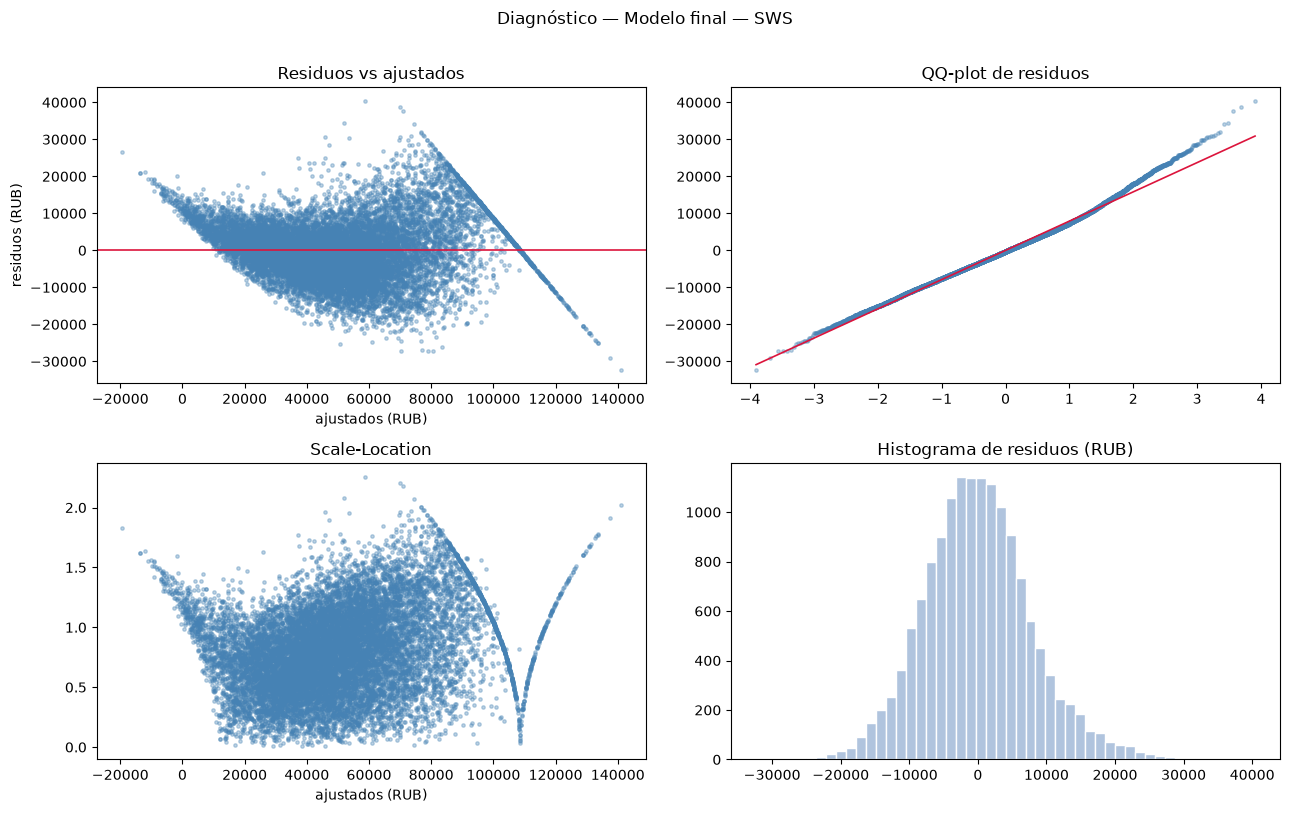

MODELO FINAL = SWS: 109 features (sin intercepto)

[continuas_binarias] (4): metro_f_z, area_f_z, furnished, pets_allowed

[building_type] (5): building_type_khrushchev, building_type_stalin, building_type_monolith, building_type_brick, building_type_modern_panel

[renovation] (3): renovation_designer, renovation_euro, renovation_no_renovation

[district] (97): district_Khamovniki, district_Arbat, district_Tverskoy, district_Presnensky, district_Yakimanka, district_Zamoskvorechye, district_Dorogomilovo, district_Basmanny, district_Meshchansky, district_Krasnoselsky, district_Tagansky, district_Krylatskoye, district_Prospekt Vernadskogo, district_Lomonosovsky, district_Gagarinsky, district_Ramenki, district_Filyovsky Park, district_Troparyovo-Nikulino, district_Kurkino, district_Akademichesky, district_Fili-Davydkovo, district_Khoroshyovsky, district_Cheryomushki, district_Shchapovskoye, district_Strogino, district_Shchukino, district_Sokol, district_Obruchevsky, district_Kuntsevo, dist

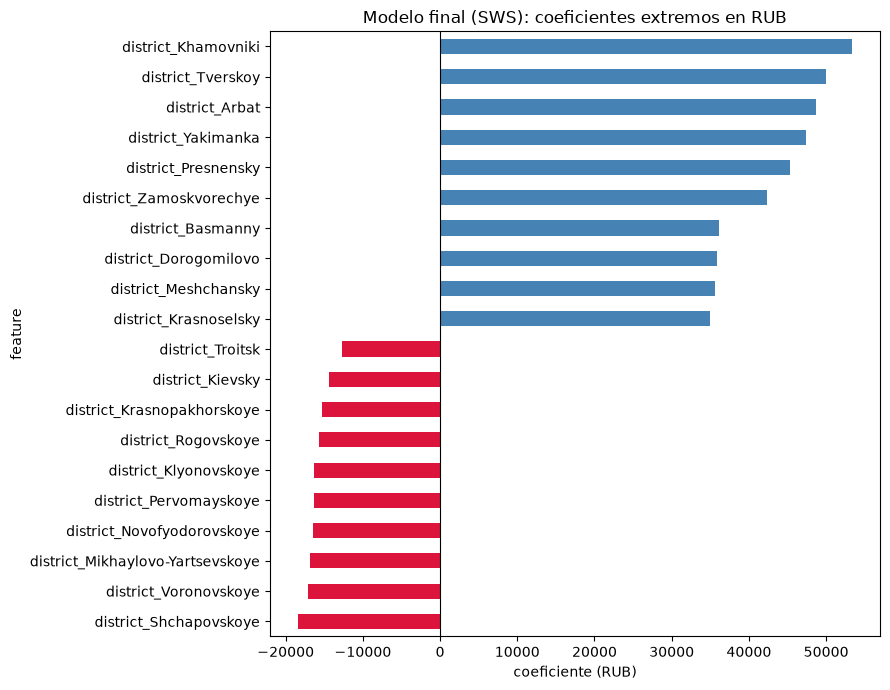

,feature,coef,std_err,t,p_valor,IC95_inf,IC95_sup,efecto_abs
4,district_Khamovniki,53384.9,791.0,67.5,0.0,51834.4,54935.4,53384.9
7,district_Tverskoy,49974.4,791.8,63.1,0.0,48422.4,51526.4,49974.4
6,district_Arbat,48704.8,740.7,65.8,0.0,47253.0,50156.6,48704.8
9,district_Yakimanka,47357.6,807.9,58.6,0.0,45774.1,48941.2,47357.6
8,district_Presnensky,45360.7,743.4,61.0,0.0,43903.6,46817.8,45360.7
11,district_Zamoskvorechye,42382.9,790.3,53.6,0.0,40833.9,43931.9,42382.9
13,district_Basmanny,36178.9,735.0,49.2,0.0,34738.2,37619.7,36178.9
12,district_Dorogomilovo,35909.8,698.1,51.4,0.0,34541.3,37278.2,35909.8
14,district_Meshchansky,35652.7,790.8,45.1,0.0,34102.7,37202.7,35652.7
15,district_Krasnoselsky,34937.3,788.8,44.3,0.0,33391.1,36483.4,34937.3


In [15]:
res_final = bateria_ols(modelo_final, FINAL_COLS, f"Modelo final — {FINAL_NOMBRE}")
print(f"MODELO FINAL = {FINAL_NOMBRE}: {len(FINAL_COLS)} features (sin intercepto)")
for b in ["continuas_binarias", "building_type", "renovation", "district"]:
    cols_b = [c for c in FINAL_COLS if bloque_de(c) == b]
    print(f"\n[{b}] ({len(cols_b)}): {', '.join(cols_b) if cols_b else '(ninguna)'}")
coef_final = res_final["coef"].copy()
coef_final_sin_const = coef_final[coef_final["feature"] != "const"].copy()
if not coef_final_sin_const.empty:
    coef_final_sin_const["efecto_abs"] = coef_final_sin_const["coef"].abs()
    top_coef = coef_final_sin_const.sort_values("coef")
    seleccion = pd.concat([top_coef.head(10), top_coef.tail(10)]).drop_duplicates().sort_values("coef")
    fig_coef_final, ax = plt.subplots(figsize=(9, 7))
    colores = ["crimson" if v < 0 else "steelblue" for v in seleccion["coef"]]
    seleccion.set_index("feature")["coef"].plot.barh(ax=ax, color=colores)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"Modelo final ({FINAL_NOMBRE}): coeficientes extremos en RUB")
    ax.set_xlabel("coeficiente (RUB)"); plt.tight_layout(); plt.show()
    display(coef_final_sin_const.sort_values("efecto_abs", ascending=False).head(15).round(1))
else:
    fig_coef_final = None
    print("El modelo final no tiene coeficientes distintos del intercepto para graficar.")

,valor
sesgo_medio_train_RUB,0.000
sesgo_medio_test_RUB,5357.273
mediana_resid_test_RUB,3109.777
std_resid_train,7933.871
std_resid_test,12558.218
skew_resid_train,0.335
kurtosis_resid_train,0.637
jarque_bera_p,0.000
breusch_pagan_p,0.000
pct_resid_fuera_2std_train,5.047


Residuos por quintil de predicción (train): sesgo = mean; heterocedasticidad = std creciente entre tramos


,mean,std,count,std_relativa
tramo,,,,
q1 (baratos),2813.0,5286.0,2964,1.00
q2,-1507.0,5420.0,2964,1.03
q3,-2549.0,6580.0,2964,1.24
q4,-1974.0,8222.0,2964,1.56
q5 (caros),3217.0,10756.0,2964,2.03


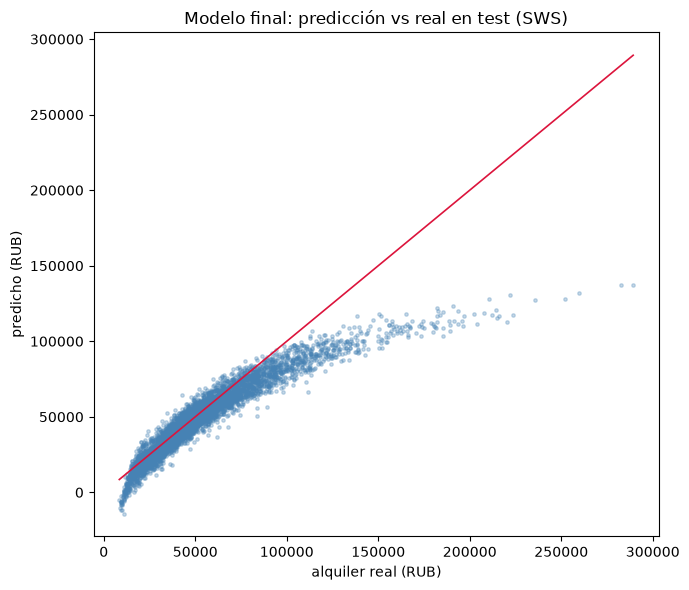

Lectura dinámica del diagnóstico (calculada en esta ejecución): sesgo medio en test = 5,357 RUB (real menos predicho); Breusch-Pagan p = 1.56e-267; razón entre el desvío de residuos del tramo más disperso y el menos disperso en train = 2.03.
Si el sesgo en test se aparta de cero, una lectura compatible es el corrimiento temporal entre el período de ajuste y el de evaluación; si la dispersión crece con el nivel predicho, el error en rublos es mayor en el segmento caro aunque el desempeño relativo sea parecido.


In [16]:
# Diagnóstico cuantitativo del final, calculado en esta ejecución (sin cifras fijadas en el texto)
resid_tr = np.asarray(modelo_final.resid, dtype=float)
pred_tr = np.asarray(modelo_final.fittedvalues, dtype=float)
resid_te = np.asarray(test[TARGET], dtype=float) - np.asarray(pred_final_test, dtype=float)
std_tr = float(resid_tr.std()) if resid_tr.std() > 0 else np.nan
cuant = pd.DataFrame({
    "sesgo_medio_train_RUB": [float(resid_tr.mean())], "sesgo_medio_test_RUB": [float(resid_te.mean())],
    "mediana_resid_test_RUB": [float(np.median(resid_te))],
    "std_resid_train": [float(resid_tr.std())], "std_resid_test": [float(resid_te.std())],
    "skew_resid_train": [float(stats.skew(resid_tr))], "kurtosis_resid_train": [float(stats.kurtosis(resid_tr))],
    "jarque_bera_p": [float(jarque_bera(resid_tr)[1])],
    "breusch_pagan_p": [float(het_breuschpagan(resid_tr, modelo_final.model.exog)[1])],
    "pct_resid_fuera_2std_train": [float((np.abs(resid_tr) > 2 * std_tr).mean() * 100)] if np.isfinite(std_tr) else [np.nan],
    "pct_esperado_normal_2std": [4.55],
    "pct_resid_fuera_3std_train": [float((np.abs(resid_tr) > 3 * std_tr).mean() * 100)] if np.isfinite(std_tr) else [np.nan],
    "pct_esperado_normal_3std": [0.27]})
display(cuant.T.rename(columns={0: "valor"}).round(3))
tramos = pd.qcut(pred_tr, 5, labels=["q1 (baratos)", "q2", "q3", "q4", "q5 (caros)"])
tab_tramos = pd.DataFrame({"tramo": tramos, "resid": resid_tr}).groupby("tramo", observed=True)["resid"].agg(["mean", "std", "count"]).round(0)
if tab_tramos["std"].min() > 0:
    tab_tramos["std_relativa"] = (tab_tramos["std"] / tab_tramos["std"].min()).round(2)
print("Residuos por quintil de predicción (train): sesgo = mean; heterocedasticidad = std creciente entre tramos")
display(tab_tramos)

fig_pred_final, ax = plt.subplots(figsize=(7, 6))
ax.scatter(test[TARGET], pred_final_test, s=6, alpha=0.3, color="steelblue")
lims = [float(test[TARGET].min()), float(test[TARGET].max())]
ax.plot(lims, lims, color="crimson", lw=1.2)
ax.set_xlabel("alquiler real (RUB)"); ax.set_ylabel("predicho (RUB)")
ax.set_title(f"Modelo final: predicción vs real en test ({FINAL_NOMBRE})")
plt.tight_layout(); plt.show()

# Interpretación generada a partir de los resultados actuales (no fijada en markdown).
_sesgo_test = float(resid_te.mean())
_bp_p = float(cuant["breusch_pagan_p"].iloc[0])
_ratio_std = float(tab_tramos["std"].max() / tab_tramos["std"].min()) if tab_tramos["std"].min() > 0 else np.nan
print(f"Lectura dinámica del diagnóstico (calculada en esta ejecución): sesgo medio en test = {_sesgo_test:,.0f} RUB (real menos predicho); "
      f"Breusch-Pagan p = {_bp_p:.3g}; razón entre el desvío de residuos del tramo más disperso y el menos disperso en train = {_ratio_std:.2f}.")
print("Si el sesgo en test se aparta de cero, una lectura compatible es el corrimiento temporal entre el período de ajuste y el de evaluación; "
      "si la dispersión crece con el nivel predicho, el error en rublos es mayor en el segmento caro aunque el desempeño relativo sea parecido.")

### Límites de interpretación

- **Sin causalidad.** Los coeficientes se interpretan como **asociaciones condicionadas** a las features incluidas y al período analizado. Que un distrito, una renovación o el amueblado aparezcan asociados a un alquiler mayor no implica que cambiar esa característica cause ese cambio de precio: puede reflejar composición de la oferta, calidad no observada o correlación con otras variables.
- **Inferencia post-selección.** En los OLS reajustados tras seleccionar con el mismo train, los p-valores e intervalos son descriptivos y exploratorios (ver nota de la sección 1). No deben presentarse como inferencia confirmatoria independiente.
- **Winsorización de train.** La target de train proviene de una etapa previa que la winsorizó dentro de su período, mientras que test conserva su distribución posterior. El modelo puede quedar conservador en el segmento alto de test, que nunca vio con esos niveles durante el ajuste. La magnitud concreta debe leerse en las tablas de residuos de esta ejecución.
- **Distribución temporal.** Train y test son períodos distintos: cambios de nivel del mercado entre 2021–2024 y 2025–2026 aparecen como sesgo y brecha train–test, no como falla de una feature puntual. El notebook no modela una tendencia temporal explícita.
- **Desbalance y colinealidad.** Las dummies de distrito, tipo de edificio y renovación son desbalanceadas (algunas categorías concentran muchas filas y otras muy pocas) y pueden estar correlacionadas entre sí y con las continuas. El VIF, el rango de la matriz y la batería de cada OLS deben revisarse antes de sobreinterpretar un coeficiente individual; ante colinealidad, statsmodels estima por pseudo-inversa y los coeficientes individuales pierden identificación aunque la predicción se sostenga.
- **Uso de test en la elección.** Si el final se eligió con la regla del 1 % en test, su métrica en test no es una evaluación independiente (ver sección 6). La comparación honesta entre métodos es la validación temporal dentro de train; test queda como comparación declarada y reutilizada para elegir.

## 8. Registro y verificación en MLflow

Todo el proceso queda registrado en el experimento **`Alquiler_v2`**: baselines, BSS agrupado, Stepwise, Lasso nativo, Random Forest nativo, los OLS reajustados, los modelos manuales sin duplicar alias y el modelo final marcado. Cada run lleva, cuando aplica: método e hiperparámetros, número de features, split, métricas de train, validación temporal y test, lista completa de features, métricas OLS y tabla de coeficientes, modelo serializado, y gráficas y tablas relevantes como artefactos (incluidas las tablas resumen, larga de features y de coeficientes en formato CSV como texto).

El destino depende de lo que haya, sin bloquear la ejecución: si está definida la credencial de DagsHub, se registra remoto; si no, el mismo código registra en MLflow local (`mlruns/`) y la verificación final se hace contra ese backend. Las ejecuciones de otros experimentos no se tocan.

In [17]:
import os

import mlflow
import mlflow.sklearn
import mlflow.statsmodels
from mlflow.tracking import MlflowClient

try:
    from dotenv import load_dotenv
    if (RAIZ / ".env").is_file():
        load_dotenv(RAIZ / ".env")
except Exception:
    pass

BACKEND = "local"
if os.environ.get("DAGSHUB_USER_TOKEN", "").strip():
    try:
        import dagshub
        dagshub.init(repo_owner="matiasgastonlonghino", repo_name="MOSCOW_IDA", mlflow=True, dvc=False)
        mlflow.set_tracking_uri("https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow")
        MlflowClient().search_experiments()
        BACKEND = "dagshub"
    except Exception as exc:
        print(f"DagsHub no disponible ({type(exc).__name__}); se registra en MLflow local.")
if BACKEND == "local":
    os.environ.setdefault("MLFLOW_ALLOW_FILE_STORE", "true")
    mlflow.set_tracking_uri(f"file:{RAIZ / 'mlruns'}")
experimento = mlflow.set_experiment("Alquiler_v2")
print(f"MLflow backend: {BACKEND} | tracking: {mlflow.get_tracking_uri()} | experimento: {experimento.name}")
assert mlflow.active_run() is None

/Users/tomasmontilla/workspace/facultad/Moscow-real-estate-market--Sales-and-rentals/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Accessing as MontillaTomas

Initialized MLflow to track repo "matiasgastonlonghino/MOSCOW_IDA"

Repository matiasgastonlonghino/MOSCOW_IDA initialized!

MLflow backend: dagshub | tracking: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow | experimento: Alquiler_v2


In [18]:
def registrar(nombre, metodo, params_extra, metricas, cols, modelo_ols=None, modelo_sk=None,
              figuras=None, textos=None, es_final=False):
    with mlflow.start_run(run_name=nombre) as run:
        mlflow.log_params({"metodo": metodo, "target": TARGET, "n_train": len(train), "n_test": len(test),
                           "n_features": len(cols) if cols else 0, "split": "train 2021-2024 / test 2025-2026",
                           "backend": BACKEND, **params_extra})
        limpias = {k: float(v) for k, v in metricas.items() if v is not None and np.isfinite(float(v))}
        if limpias:
            mlflow.log_metrics(limpias)
        mlflow.log_dict({"features": list(cols) if cols else []}, "features.json")
        if textos:
            for ruta, txt in textos.items():
                mlflow.log_text(txt, ruta)
        if modelo_ols is not None:
            coef_df = tabla_coeficientes(modelo_ols)
            mlflow.log_text(coef_df.to_csv(index=False), "coeficientes.csv")
            mlflow.statsmodels.log_model(modelo_ols, name="modelo")
        if modelo_sk is not None:
            mlflow.sklearn.log_model(modelo_sk, name="modelo", serialization_format="pickle")
        for nombre_fig, fig_ in (figuras or {}).items():
            if fig_ is not None:
                mlflow.log_figure(fig_, f"figuras/{nombre_fig}.png")
        if es_final:
            mlflow.set_tag("modelo_final", "true")
        return run.info.run_id

def mets_ols_completas(nombre, cols):
    m = modelos_ols[nombre]
    fila = tabla_ols.loc[tabla_ols["modelo"] == nombre].iloc[0]
    mets = {"R2_train": fila["R2_train"], "Adj_R2_train": fila["Adj_R2_train"], "F_train": fila["F_train"],
            "AIC_train": fila["AIC_train"], "BIC_train": fila["BIC_train"], "LogLik_train": fila["LogLik_train"],
            "RMSE_RUB_train": fila["RMSE_RUB_train"], "MAE_RUB_train": fila["MAE_RUB_train"],
            "R2_validacion": fila["R2_validacion"], "RMSE_RUB_validacion": fila["RMSE_RUB_validacion"], "MAE_RUB_validacion": fila["MAE_RUB_validacion"],
            "R2_test": fila["R2_test"], "RMSE_RUB_test": fila["RMSE_RUB_test"], "MAE_RUB_test": fila["MAE_RUB_test"]}
    # Nombres compatibles con MLflow (sin guiones bajos duplicados innecesarios, todo float finito).
    return m, {k: float(v) for k, v in mets.items()}

_textos_comparacion = {
    "tablas/tabla_resumen.csv": tabla_resumen.to_csv(index=False),
    "tablas/tabla_nativos.csv": tabla_nativos.to_csv(index=False),
    "tablas/tabla_ols.csv": tabla_ols.to_csv(index=False),
    "tablas/tabla_features_larga.csv": tabla_features_larga.to_csv(index=False),
    "tablas/tabla_coeficientes_ols.csv": tabla_coef_todos_ols.to_csv(index=False),
    "tablas/coeficientes_lasso.csv": tabla_coef_lasso.to_csv(index=False),
    "tablas/importancias_random_forest.csv": tabla_importancias_rf.to_csv(index=False),
}

runs = {}
runs["Baseline_ingenuo"] = registrar(
    "Baseline_ingenuo", "mediana_train", {},
    {"RMSE_RUB_train": m_naive_train["RMSE_RUB"], "MAE_RUB_train": m_naive_train["MAE_RUB"], "R2_train": m_naive_train["R2"],
     "RMSE_RUB_validacion": rmse_wf_naive, "MAE_RUB_validacion": mae_wf_naive,
     "RMSE_RUB_test": m_naive_test["RMSE_RUB"], "MAE_RUB_test": m_naive_test["MAE_RUB"], "R2_test": m_naive_test["R2"]},
    [], textos={"baseline.txt": f"mediana train = {mediana_train:,.0f} RUB", **_textos_comparacion})
m_c, met_c = mets_ols_completas("OLS_completo", FEATURES_BASE)
runs["Baseline_OLS_completo"] = registrar(
    "Baseline_OLS_completo", "ols_completo", {}, met_c, FEATURES_BASE, modelo_ols=m_c,
    figuras={"diagnostico": res_completo["figura"]},
    textos={"summary.txt": m_c.summary().as_text(), **_textos_comparacion})
for nombre, bss in [("BSS_okrug", bss_okrug), ("BSS_precio_venta", bss_precio)]:
    if nombre not in modelos_ols:
        continue
    m_b, met_b = mets_ols_completas(nombre, bss["cols"])
    runs[nombre] = registrar(nombre, "best_subset_agrupado", {"k_bloques": bss["k"], "n_bloques": bss["n_bloques"],
                             "combinaciones_evaluadas": bss["combinaciones_evaluadas"]}, met_b, bss["cols"], modelo_ols=m_b,
                             figuras={"bic_por_k": bss["figura"]},
                             textos={"summary.txt": m_b.summary().as_text(), "tabla_bss.csv": bss["tabla"].to_csv(index=False), **_textos_comparacion})
if "SWS" in modelos_ols:
    m_s, met_s = mets_ols_completas("SWS", sws["cols"])
    runs["SWS"] = registrar("SWS", "forward_stepwise_bic", {"mejora_minima_bic": 2.0}, met_s, sws["cols"], modelo_ols=m_s,
                            figuras={"camino_bic": sws["figura"]},
                            textos={"summary.txt": m_s.summary().as_text(), "historial.csv": sws["tabla"].to_csv(index=False), **_textos_comparacion})
# Predictores nativos
_fila_lasso_n = tabla_nativos.loc[tabla_nativos["modelo"] == "Lasso_nativo"].iloc[0]
runs["Lasso_nativo"] = registrar(
    "Lasso_nativo", "lasso", {"alpha": ALPHA_LASSO, "fraccion_alpha_max": FRAC_LASSO_ELEGIDA, "tolerancia_coef": TOL_LASSO, "n_features_entrada": len(FEATURES_BASE), "n_features_seleccionadas": len(cols_lasso)},
    {"R2_train": _fila_lasso_n["R2_train"], "RMSE_RUB_train": _fila_lasso_n["RMSE_RUB_train"], "MAE_RUB_train": _fila_lasso_n["MAE_RUB_train"],
     "R2_validacion": _fila_lasso_n["R2_validacion"], "RMSE_RUB_validacion": _fila_lasso_n["RMSE_RUB_validacion"], "MAE_RUB_validacion": _fila_lasso_n["MAE_RUB_validacion"],
     "R2_test": _fila_lasso_n["R2_test"], "RMSE_RUB_test": _fila_lasso_n["RMSE_RUB_test"], "MAE_RUB_test": _fila_lasso_n["MAE_RUB_test"]},
    list(FEATURES_BASE), modelo_sk=lasso_pipe, figuras={"curva_alpha": fig_lasso},
    textos={"coeficientes_lasso.csv": tabla_coef_lasso.to_csv(index=False), "features_seleccionadas.txt": ", ".join(cols_lasso), **_textos_comparacion})
_fila_rf_n = tabla_nativos.loc[tabla_nativos["modelo"] == "RandomForest_nativo"].iloc[0]
runs["RandomForest_nativo"] = registrar(
    "RandomForest_nativo", "random_forest", {"max_depth": str(prof_g), "min_samples_leaf": hoja_g, "n_estimators": 300, "random_state": 42,
     "criterio_seleccion": "prefijo minimo del ranking con importancia acumulada >= 90%", "n_features_entrada": len(FEATURES_BASE), "n_features_seleccionadas": len(cols_rf)},
    {"R2_train": _fila_rf_n["R2_train"], "RMSE_RUB_train": _fila_rf_n["RMSE_RUB_train"], "MAE_RUB_train": _fila_rf_n["MAE_RUB_train"],
     "R2_validacion": _fila_rf_n["R2_validacion"], "RMSE_RUB_validacion": _fila_rf_n["RMSE_RUB_validacion"], "MAE_RUB_validacion": _fila_rf_n["MAE_RUB_validacion"],
     "R2_test": _fila_rf_n["R2_test"], "RMSE_RUB_test": _fila_rf_n["RMSE_RUB_test"], "MAE_RUB_test": _fila_rf_n["MAE_RUB_test"]},
    list(FEATURES_BASE), modelo_sk=rf_full, figuras={"importancias": fig_rf},
    textos={"importancias.csv": tabla_importancias_rf.to_csv(index=False), "features_seleccionadas.txt": ", ".join(cols_rf), **_textos_comparacion})
# OLS reajustados desde selectores y manuales no alias (sin duplicar baselines ya registrados)
for nombre in ["OLS_desde_Lasso", "OLS_desde_RF"] + [k for k in MANUALES if k not in ALIAS_MANUALES]:
    if nombre not in modelos_ols:
        continue
    m_o, met_o = mets_ols_completas(nombre, candidatos_ols[nombre])
    _selector = nombre.replace("OLS_desde_", "") if nombre.startswith("OLS_desde_") else "manual"
    _extra = {"selector": _selector}
    if nombre in MANUALES:
        _extra["hipotesis"] = MANUALES[nombre]["hipotesis"][:250]
    runs[nombre] = registrar(nombre, "ols_reajustado" if nombre.startswith("OLS_desde_") else "ols_manual", _extra,
                             met_o, candidatos_ols[nombre], modelo_ols=m_o,
                             textos={"summary.txt": m_o.summary().as_text(), **_textos_comparacion})
# Alias: se deja constancia sin crear runs duplicados.
for _alias, _canon in {**ALIAS_OLS, **ALIAS_MANUALES}.items():
    print(f"Alias sin run duplicado: {_alias} == {_canon} (mismo conjunto exacto de features).")
# Modelo final: alias del run canónico o run propio marcado.
_canon_final_run = {"OLS_completo": "Baseline_OLS_completo"}.get(FINAL_NOMBRE, FINAL_NOMBRE)
if _canon_final_run in runs:
    MlflowClient().set_tag(runs[_canon_final_run], "modelo_final", "true")
    runs["Modelo_final"] = runs[_canon_final_run]
    print(f"Modelo final {FINAL_NOMBRE}: se marcó el run existente {_canon_final_run} como final, sin duplicar.")
else:
    m_f, met_f = mets_ols_completas(FINAL_NOMBRE, FINAL_COLS)
    runs["Modelo_final"] = registrar("Modelo_final", "ols_final", {"origen": FINAL_NOMBRE}, met_f, FINAL_COLS,
                                     modelo_ols=m_f, es_final=True,
                                     figuras={"diagnostico": res_final["figura"]},
                                     textos={"summary.txt": m_f.summary().as_text(), **_textos_comparacion})
print(f"Runs registrados en esta ejecución: {len(set(runs.values()))} runs únicos ({len(runs)} claves, incluyendo el alias del modelo final) en el experimento Alquiler_v2 (backend {BACKEND})")

🏃 View run Baseline_ingenuo at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6/runs/ec623d12235b4d478c0784a85bf83fd8
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6


🏃 View run Baseline_OLS_completo at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6/runs/93b8a5b6db7b4a63b6ff417f73eda377
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6


🏃 View run SWS at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6/runs/0a93a1e6f2964209b50724bfd8428e6c
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6


2026/10/27 14:25:37 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run Lasso_nativo at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6/runs/2cdced6c505241829cafd6410cef6044
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6


...

🏃 View run Manual_ubicacion at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6/runs/4dd7b90895254112995505169072a207
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6


🏃 View run Manual_caracteristicas_vivienda at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6/runs/b4b85a90189e4dfb8d9b6e955bb885ef
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6


🏃 View run Manual_superficie_ubicacion at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6/runs/fd3d67b15cf04292bc5a36fcffa7ce49
🧪 View experiment at: https://dagshub.com/matiasgastonlonghino/MOSCOW_IDA.mlflow/#/experiments/6


Alias sin run duplicado: BSS_okrug == OLS_completo (mismo conjunto exacto de features).
Alias sin run duplicado: BSS_precio_venta == OLS_completo (mismo conjunto exacto de features).
Alias sin run duplicado: OLS_desde_Lasso == OLS_completo (mismo conjunto exacto de features).
Alias sin run duplicado: Manual_vivienda_ubicacion == OLS_completo (mismo conjunto exacto de features).


Modelo final SWS: se marcó el run existente SWS como final, sin duplicar.
Runs registrados en esta ejecución: 10 runs únicos (11 claves, incluyendo el alias del modelo final) en el experimento Alquiler_v2 (backend dagshub)


In [19]:
cliente = MlflowClient()
encontrados = cliente.search_runs([experimento.experiment_id])
propios = [r for r in encontrados if r.info.run_id in set(runs.values())]
verif = pd.DataFrame([{"run": r.data.tags.get("mlflow.runName", "?"), "estado": r.info.status,
                       "n_metricas": len(r.data.metrics)} for r in propios])
display(verif)
assert len(propios) == len(set(runs.values())) and (verif["estado"] == "FINISHED").all(), "La verificación de runs no coincide con lo registrado"
final_id = cliente.get_run(runs["Modelo_final"])
assert final_id.data.tags.get("modelo_final") == "true", "El run final no quedó marcado"
artefactos_final = {a.path for a in cliente.list_artifacts(runs["Modelo_final"], "figuras")} | \
                   {a.path for a in cliente.list_artifacts(runs["Modelo_final"])}
print(f"Verificados {len(propios)} runs únicos FINISHED en backend {BACKEND}; artefactos del run final: {sorted(artefactos_final)[:8]}")
print(f"Comparación en test: el final {FINAL_NOMBRE} ({len(FINAL_COLS)} features) quedó dentro de la banda del 1% del mejor RMSE entre OLS ({mejor_rmse:,.0f} RUB). "
      f"Como test se usó para elegir, ese valor no es una evaluación final independiente.")

,run,estado,n_metricas
0,Manual_superficie_ubicacion,FINISHED,14
1,Manual_caracteristicas_vivienda,FINISHED,14
2,Manual_ubicacion,FINISHED,14
3,Manual_superficie,FINISHED,14
4,OLS_desde_RF,FINISHED,14
5,RandomForest_nativo,FINISHED,9
6,Lasso_nativo,FINISHED,9
7,SWS,FINISHED,14
8,Baseline_OLS_completo,FINISHED,14
9,Baseline_ingenuo,FINISHED,8


Verificados 10 runs únicos FINISHED en backend dagshub; artefactos del run final: ['coeficientes.csv', 'features.json', 'figuras', 'figuras/camino_bic.png', 'historial.csv', 'summary.txt', 'tablas']
Comparación en test: el final SWS (109 features) quedó dentro de la banda del 1% del mejor RMSE entre OLS (13,584 RUB). Como test se usó para elegir, ese valor no es una evaluación final independiente.


## Cierre

El modelo que queda es el OLS reajustado que la regla de parsimonia eligió en la comparación de la sección 6: el subconjunto más chico a menos del 1 % del mejor error en test entre los OLS comparables, con su batería completa en la sección 7 y su run marcado como final en MLflow. Los métodos automáticos quedan registrados como predictores nativos, cuando corresponde, y como selectores cuyo subconjunto se reajusta en un OLS común; los modelos manuales quedan como hipótesis explícitas previas a test, con sus alias declarados y sin runs duplicados.